# SINGLE CELLS 

## 1. Data exploration

We begin by exploring the structure and quality of the dataset at both the cell and gene level to ensure that the data is suitable for downstream analysis and to characterize the main sources of biological variability.

In [3]:
import anndata
import scipy.sparse as sp

# --- Load the single-cell dataset ---
df = anndata.read_h5ad("single_cell.h5ad")

# --- Basic summary of the AnnData object ---
print("AnnData object:")
print(df)
print("\n" + "-"*60)

# --- Dimensions of the expression matrix ---
print("Expression matrix (adata.X) shape:")
print(f"  - Number of cells (rows):    {df.X.shape[0]}")
print(f"  - Number of genes (columns): {df.X.shape[1]}")
print("\n" + "-"*60)

# --- Check whether the matrix is sparse or dense ---
print("Matrix type:")
print(f"  adata.X type: {type(df.X)}")
if sp.issparse(df.X):
    print("  → The expression matrix is sparse.")
else:
    print("  → The expression matrix is dense.")
print("\n" + "-"*60)

# --- Gene and cell metadata dimensions ---
print("Metadata tables:")
print(f"  - Number of entries in adata.var (genes): {df.var.shape[0]}")
print(f"  - Number of entries in adata.obs (cells): {df.obs.shape[0]}")
print("\n" + "-"*60)

# --- Display the first rows of gene and cell metadata ---
print("First rows of adata.var (gene metadata):")
print(df.var.head())
print("\n" + "-"*60)

print("First rows of adata.obs (cell metadata):")
print(df.obs.head())
print("\n" + "-"*60)

# --- Small preview of the expression matrix ---
print("Preview of adata.X (expression matrix):")
print(df.X[:5, :5])  




AnnData object:
AnnData object with n_obs × n_vars = 1499 × 4290
    obs: 'ID'
    var: 'ENSG', 'Symbol'

------------------------------------------------------------
Expression matrix (adata.X) shape:
  - Number of cells (rows):    1499
  - Number of genes (columns): 4290

------------------------------------------------------------
Matrix type:
  adata.X type: <class 'numpy.ndarray'>
  → The expression matrix is dense.

------------------------------------------------------------
Metadata tables:
  - Number of entries in adata.var (genes): 4290
  - Number of entries in adata.obs (cells): 1499

------------------------------------------------------------
First rows of adata.var (gene metadata):
                 ENSG  Symbol
0  ENSMUSG00000030159  Clec1b
1  ENSMUSG00000053470   Kdm3a
2  ENSMUSG00000041729  Coro2b
3  ENSMUSG00000048489   Depp1
4  ENSMUSG00000046080  Clec9a

------------------------------------------------------------
First rows of adata.obs (cell metadata):
           I

**Gene Expression**

Single-cell RNA sequencing (scRNA-seq) enables the quantification of **gene expression** at the resolution of individual cells.
All cells in a multicellular organism contain the same genome, but they activate different subsets of genes depending on their identity and function.  
A **gene** is a DNA sequence that encodes a protein.  
To produce a protein, the gene must first be transcribed into messenger RNA (mRNA):

$$
\text{DNA} \rightarrow \text{mRNA} \rightarrow \text{Protein}.
$$

The amount of mRNA produced for each gene is called **gene expression**, and it varies widely between cell types.  
For this reason, the **transcriptional profile** of a cell uniquely reflects its biological identity.

**Dataset structure**

The dataset is stored as an `AnnData` object, where the main component is the expression matrix:

$$
X \in \mathbb{R}^{n_{\text{cells}} \times n_{\text{genes}}}
$$

In our case:

- **1499 cells** (observations)  
- **4290 genes** (variables)

Each **row** $X_{i,*}$ represents the expression profile of the *i-th cell*, while each **column** $X_{*,j}$ corresponds to the *j-th gene*, measured across all cells.
Therefore, each `df.X` matrix entry $(X_{i,j})$ represents the **normalized and log1p-transformed expression level of gene \(j\) in cell \(i\)**.

This transformation (`log1p = log(1 + x)`) is commonly used in scRNA-seq preprocessing to stabilize variance, reduce the dominance of highly expressed genes, and mitigate the effects of data sparsity.

In this dataset, the expression matrix `df.X` may be stored either as a dense NumPy array or as a sparse matrix.  
Sparse storage is very common in single-cell RNA sequencing because most genes are not expressed in most cells, resulting in a large number of zero values. Storing only the non-zero entries greatly reduces memory usage and improves computational efficiency for large datasets.

However, given the size of our dataset (1499 × 4290), both dense and sparse formats are computationally manageable and do not pose performance issues. Importantly, **the choice between dense and sparse storage affects only how the matrix is represented in memory and does not change the biological meaning of the gene expression values**. All downstream analyses (normalization, dimensionality reduction, clustering, classification) operate identically regardless of whether `df.X` is stored in dense or sparse format.

**Gene annotation and organism of origin**

Gene metadata (`df.var`) include both Ensembl gene identifiers and gene symbols.  
All Ensembl IDs in the dataset begin with **“ENSMUSG”**, and all symbols follow the *Mus musculus* capitalization convention (one capital letter followed by lowercase characters, e.g., *Clec1b*, *Kdm3a*).  
This indicates that **all genes, and therefore all cells, originate from the mouse (*Mus musculus*)**.

**Cell annotation**
At this stage, `df.obs` contains only the cell identifiers, and the FACS-derived cell type labels are not yet included in the object.

**scRNA-seq**

The scRNA-seq workflow consists of:

1. **Cell isolation**  
2. **RNA capture and reverse transcription** into cDNA  
3. **Sequencing** of the cDNA  
4. **Alignment** of sequencing reads to a reference genome  
5. **Quantification** of gene expression  
6. **Normalization and log1p transformation**
 
The resulting processed expression values are stored in `df.X` and used for downstream analysis.


**FACS-based labels**

Before sequencing, cells were separated using **Fluorescence-Activated Cell Sorting (FACS)**.  
FACS uses fluorescent antibodies that bind to specific surface proteins; since different cell types express distinct markers (e.g., CD3 for T cells, CD19/CD20 for B cells, CD14 for monocytes), the instrument can isolate biologically coherent cell populations.

These FACS-derived labels represent the **ground truth** for the supervised learning task.  
Thus, scRNA-seq provides the **features** (gene expression), while FACS provides the **labels** (true cell type) used as the target variable.

**Goal of the project**

The objective of this assignment is to use the single-cell expression matrix to **predict the FACS-assigned cell type** of each cell.

- **Input:** a 4290-dimensional gene expression vector for each cell (one row of `df.X`)  
- **Output:** a predicted cell type  
- **Task:** supervised multiclass classification  

Compared to the SNP dataset used previously, scRNA-seq data are inherently more complex because they are:

- **noisy** (due to stochastic transcription and technical variability)    
- influenced by **cell-cycle effects**, **stress**, **mitochondrial content**, and **batch effects**  
- biologically dynamic (gene expression can change rapidly)

As a result, predictive performance is expected to be lower than with genotype data, even when applying the same machine learning methods.

### 1.1 Quality control metrics

Before performing any deeper analysis, it is essential to evaluate basic quality control (QC) metrics for each cell.  
Single-cell RNA-seq data are inherently noisy, and some cells may be low-quality, damaged, or poorly captured.  
QC metrics allow us to detect these artifacts and better understand the overall structure of the dataset.

In this section, we compute three key QC measures:

1. **Number of detected genes per cell (`n_genes`)**  
   This reflects the complexity of each cell's transcriptome.  
   Cells with very few detected genes may be dead, damaged, or sequenced at low depth.

2. **Total counts per cell (`total_counts`)**  
   This corresponds to the total expression measured in each cell.  
   Extremely high values may indicate *doublets* (two cells captured together).

3. **Percentage of mitochondrial gene expression (`pct_mito`)**  
   Mitochondrial genes increase when a cell is stressed or undergoing apoptosis.  
   A high percentage suggests poor-quality or dying cells.

These metrics together provide a first overview of data quality and help identify possible technical biases such as dropout, low sequencing depth, or cell stress. Although we will not remove cells at this stage, understanding these metrics is foundamental to interpret downstream results.

In [4]:
import numpy as np

# 1. Number of detected genes per cell
df.obs["n_genes"] = (df.X > 0).sum(axis=1)

# 2. Total counts per cell
df.obs["total_counts"] = df.X.sum(axis=1)

# 3. Percentage of mitochondrial RNA
# Identify mitochondrial genes in df.var
mt_genes = df.var_names.str.startswith(("mt-", "MT-"))
df.obs["pct_mito"] = (df.X[:, mt_genes].sum(axis=1) / df.obs["total_counts"]) * 100

df.obs.head()

,ID,n_genes,total_counts,pct_mito
0,f8f4122d32,2387,10542.946245,0.0
1,c547632b57,2546,11014.860411,0.0
2,c2e46e7dfc,2517,10672.418858,0.0
3,0710f78e38,2322,12392.413905,0.0
4,449e822f38,2553,9953.476035,0.0


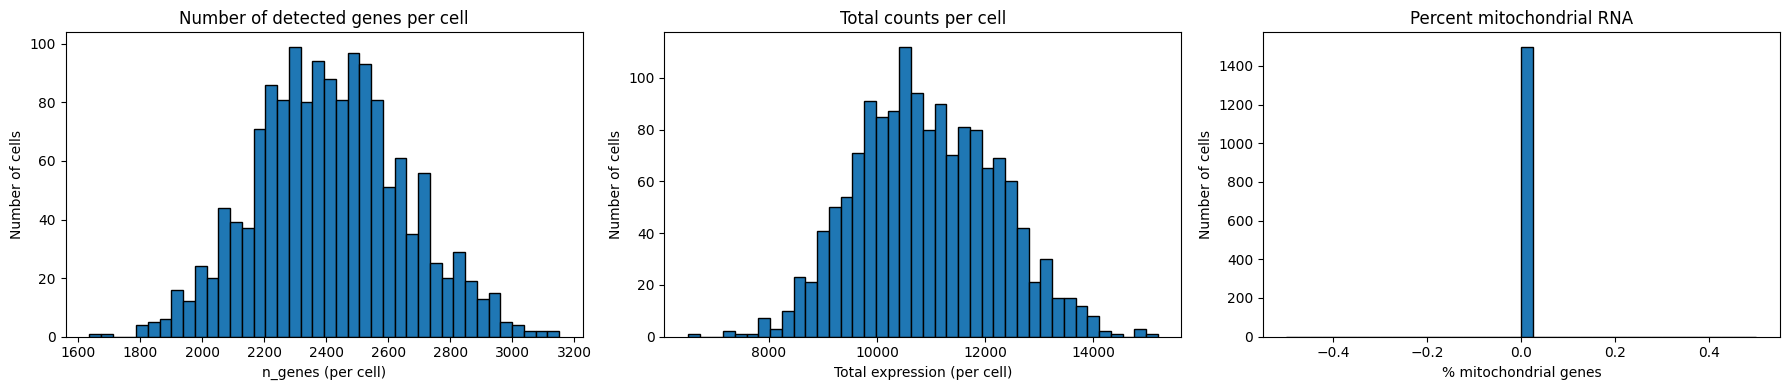

In [5]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 3, figsize=(18, 4))

# Histogram of number of detected genes per cell
axs[0].hist(df.obs["n_genes"], bins=40, edgecolor="black")
axs[0].set_title("Number of detected genes per cell")
axs[0].set_xlabel("n_genes (per cell)")
axs[0].set_ylabel("Number of cells")

# Histogram of total counts per cell
axs[1].hist(df.obs["total_counts"], bins=40, edgecolor="black")
axs[1].set_title("Total counts per cell")
axs[1].set_xlabel("Total expression (per cell)")
axs[1].set_ylabel("Number of cells")

# Histogram of percent mitochondrial RNA
axs[2].hist(df.obs["pct_mito"], bins=40, edgecolor="black")
axs[2].set_title("Percent mitochondrial RNA")
axs[2].set_xlabel("% mitochondrial genes")
axs[2].set_ylabel("Number of cells")

plt.tight_layout()
plt.show()

The three QC metrics computed above provide a first overview of the quality and structure of the dataset.

It is important to note that the values in `df.X` are already normalized and log1p-transformed.  
For this reason, the metric `total_counts` does not represent raw UMI counts, and its scale differs from what is typically observed in unprocessed 10x scRNA-seq datasets.

- **Number of detected genes (`n_genes`)**  
  Most cells express between ~1,800 and ~2,800 genes within the panel of 4,290 genes included in the dataset.  
  This range is typical for single-cell datasets after preprocessing and indicates that cells retain a reasonable transcriptional complexity.

- **Total counts per cell (`total_counts`)**  
  Because the data are normalized, the total expression values span a compressed range (approximately a few hundred to ~1500).  
  This is expected given the transformation applied to the dataset and does not correspond to raw sequencing depth.

- **Percent mitochondrial RNA (`pct_mito`)**  
  All cells show a 0% mitochondrial fraction, indicating that no mitochondrial genes are present in `df.var`.  
  As a result, this QC metric is not informative in this dataset.

Overall, these QC distributions are consistent with a dataset that has already undergone substantial preprocessing.  
The values do not reflect raw molecule counts but normalized expression magnitudes, and therefore should be interpreted accordingly.

### 1.2 Gene-level exploration

After examining cell-level quality metrics, we now explore the genes themselves.  
In single-cell RNA-seq, genes show very different expression behaviours across cells:

- some genes are expressed in almost all cells, often housekeeping genes (genes that are required for basic cellular functions)
- some are expressed only in specific subpopulations,
- many are expressed at very low levels or are detected in only a few cells

Understanding this distribution helps evaluate the overall structure of the dataset and the potential biological signals it contains.

In this section, we compute gene-level statistics such as:

- **mean expression** across all cells,  
- **variance**,  
- **number of cells in which each gene is detected**,  
- **identification of genes that are never expressed**.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Mean expression per gene
df.var["mean_expression"] = np.array(df.X.mean(axis=0)).ravel()

# 2. Variance per gene
df.var["variance"] = np.array(df.X.var(axis=0)).ravel()

# 3. Number of cells in which each gene is detected (>0)
df.var["n_cells_expressed"] = (df.X > 0).sum(axis=0).A1 if hasattr(df.X, "A1") else (df.X > 0).sum(axis=0).ravel()

df.var.head()


,ENSG,Symbol,mean_expression,variance,n_cells_expressed
0,ENSMUSG00000030159,Clec1b,0.180325,0.503687,175
1,ENSMUSG00000053470,Kdm3a,2.770018,9.276287,1022
2,ENSMUSG00000041729,Coro2b,0.804925,3.071210,494
3,ENSMUSG00000048489,Depp1,0.389924,2.144691,180
4,ENSMUSG00000046080,Clec9a,0.070278,0.315078,47


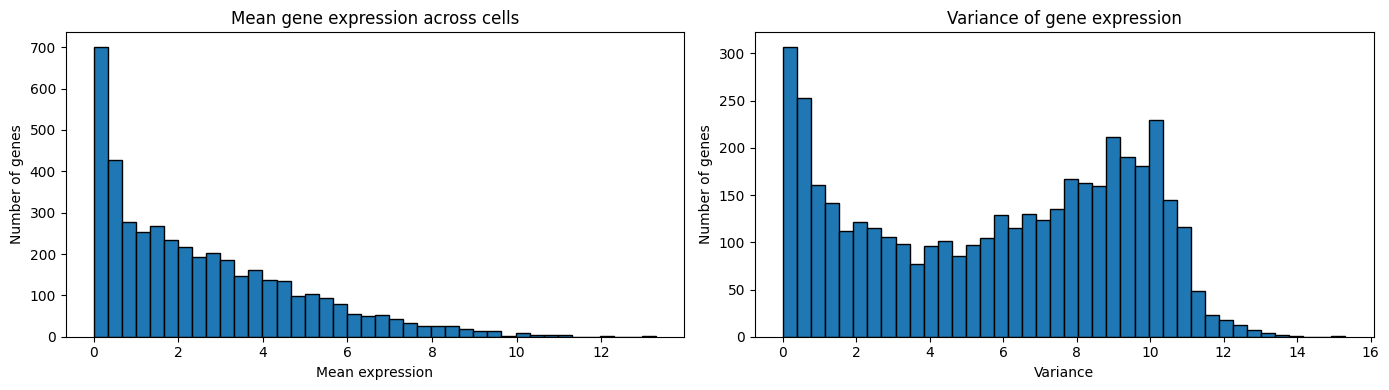

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4))

# Histogram of mean expression
axs[0].hist(df.var["mean_expression"], bins=40, edgecolor="black")
axs[0].set_title("Mean gene expression across cells")
axs[0].set_xlabel("Mean expression")
axs[0].set_ylabel("Number of genes")

# Histogram of variance
axs[1].hist(df.var["variance"], bins=40, edgecolor="black")
axs[1].set_title("Variance of gene expression")
axs[1].set_xlabel("Variance")
axs[1].set_ylabel("Number of genes")

plt.tight_layout()
plt.show()

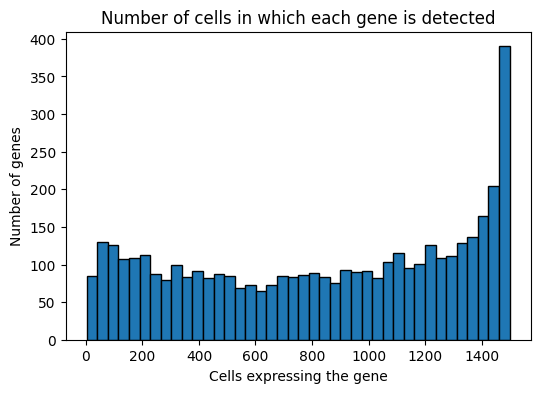

In [8]:
plt.figure(figsize=(6,4))
plt.hist(df.var["n_cells_expressed"], bins=40, edgecolor="black")
plt.title("Number of cells in which each gene is detected")
plt.xlabel("Cells expressing the gene")
plt.ylabel("Number of genes")
plt.show()

In [9]:
n_zero_genes = (df.var["n_cells_expressed"] == 0).sum()
n_zero_genes

np.int64(0)

The gene-level exploration highlights several important properties of the dataset.  

**1. Mean expression across cells**

The distribution of mean expression values is typical of single-cell RNA-seq data, especially after normalization and log-transformation, where:

- the majority of genes are expressed at low or moderate levels,  
- only a small subset exhibits strong expression across many cells.

Such a right-skewed distribution suggests the presence of both widely expressed genes (often involved in basic cellular functions) and genes with specialized or context-dependent roles.

**2. Variance of gene expression**

The variance distribution reveals substantial heterogeneity among genes:

- many genes show low variance, meaning that their expression is relatively stable across the 1499 cells,  
- other genes display much higher variability, indicating that they differ strongly between cells or cell populations.

High-variance genes are typically more informative for downstream analysis (such as clustering or cell-type identification), because they capture biological differences rather than global background expression.

**3. Number of cells in which each gene is detected**

The distribution of `n_cells_expressed` spans the entire possible range, from genes detected in only a few cells to genes expressed in almost all cells.  
This broad range indicates a mixture of:

- **cell-type–specific genes**, expressed only in particular subsets of cells  
- **ubiquitously expressed genes**, likely including housekeeping genes and other genes required for general cellular maintenance.

Notably, no gene has `n_cells_expressed = 0`, meaning that every gene in the dataset is detected in at least one cell.  
This suggests that the dataset has already undergone filtering to remove unexpressed or uninformative genes.

Taken together, these gene-level metrics show that the dataset contains a balanced combination of low-variance genes and highly variable genes, as well as genes expressed broadly or selectively across cell populations.  
This structure is characteristic of a well-preprocessed single-cell RNA-seq dataset.



### 1.3 Identification of highly variable genes (HVGs)

In single-cell RNA-seq data, not all genes contribute equally to distinguishing biological differences among cells.  
Some genes display little variability and are expressed at relatively constant levels, while others vary strongly across the cell population.  
Genes in this category, the **highly variable genes (HVGs)**, typically carry the most useful information for downstream analysis such as dimensionality reduction, clustering, and cell-type classification.

The goal of this step is to identify the genes whose expression varies the most beyond what is expected from technical noise.

In [10]:
#!pip install scanpy

In [11]:
import scanpy as sc
sc.__version__

/var/folders/4x/qywktdrx5h56ptgh_y14j73c0000gn/T/ipykernel_51547/3407629948.py:2: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  sc.__version__


'1.11.5'

In [12]:
#plot genes in function of their var

In [13]:
import scanpy as sc

# Identify highly variable genes
sc.pp.highly_variable_genes(df, n_top_genes=2000)

# Summary of how many genes were selected
df.var["highly_variable"].value_counts()

highly_variable
False    2290
True     2000
Name: count, dtype: int64

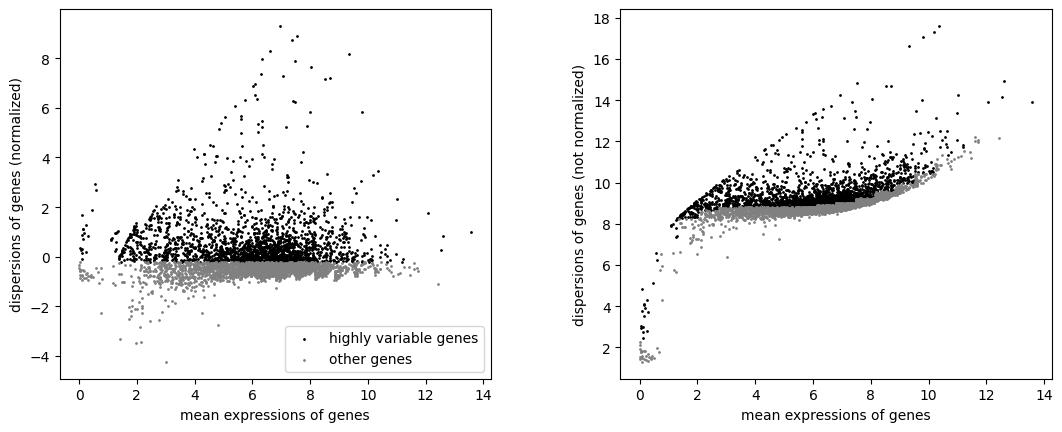

In [14]:
sc.pl.highly_variable_genes(df)

The identification of highly variable genes allows us to determine which genes carry the strongest biological signal in the dataset. Scanpy selected **2000 HVGs** out of 4290 total genes, indicating that almost half of the gene set shows substantial variability across cells.

The mean–variance relationship is visualized in the two plots:

**(Left) Normalized dispersion:**  
Genes with similar mean expression levels are expected to show similar variance. **The black points represent genes whose normalized dispersion is significantly higher than this expectation, and these genes are selected as HVGs**. The grey points follow the expected trend and are considered non-informative for distinguishing cell populations.

**(Right) Raw (unnormalized) dispersion:**  
Here the variance naturally increases with mean expression. Although this view reflects technical and biological variability, it is the normalized dispersion (left panel) that is used to select HVGs.

Biologically, HVGs typically include markers that differ across cell types or functional states, while genes with low dispersion often correspond to housekeeping or broadly expressed genes. The presence of a large number of HVGs confirms that the dataset contains strong structure and meaningful differences between cells, which will be informative for dimensionality reduction and classification.

In [15]:
# Extract highly variable genes sorted by normalized dispersion
top_hvg = df.var[df.var["highly_variable"]].sort_values("dispersions_norm", ascending=False)

# Show the top 10 HVGs
top_hvg[["Symbol", "mean_expression", "variance", "dispersions_norm"]].head(10)

,Symbol,mean_expression,variance,dispersions_norm
3536,Retnlg,0.095958,0.438039,9.298980
4029,Ngp,0.182642,0.747398,8.877937
2664,Prss34,0.166520,0.837950,8.725966
816,Trgc1,0.186706,0.855865,8.297394
844,S100a9,0.497049,2.566420,8.164399
3839,Lcn2,0.321090,1.320137,7.966299
394,Igll1,0.340141,1.141278,7.886826
3986,H2-Aa,1.402213,6.451542,7.646832
3727,Prg3,0.156183,0.734114,7.365211
4004,H2-Eb1,0.965729,4.346470,7.299795


The top highly variable genes reflect strong transcriptional differences among immune cell populations, consistent with the FACS-based origin of the dataset. Several of the most variable genes are well-known markers of specific leukocyte subsets:

- **Retnlg, Ngp, Prss34, S100a9, Lcn2, Prg3**: genes associated with neutrophils or other granulocytic lineages. Their restricted expression explains the high dispersion values.
- **Trgc1**: a T-cell receptor gamma constant gene, marking γδ T-cell subsets.
- **H2-Aa and H2-Eb1**: components of the MHC class II complex, characteristic of professional antigen-presenting cells such as dendritic cells, macrophages, and B cells.
- **IglI1**: immunoglobulin-like gene associated with B-cell–related populations.

The presence of genes linked to granulocytes, antigen-presenting cells, T-cell subsets, and B cells indicates that the dataset contains multiple immune cell types with well-defined transcriptional programs. This confirms that the dataset carries strong biological structure and that the HVGs capture meaningful sources of cell-type heterogeneity.

### Summary data exploration

The dataset shows overall high quality at both the cell and gene level. All 1499 cells display reasonable transcript complexity, with no outliers or signs of stress or degradation. As expected from the preprocessing pipeline, mitochondrial expression is absent, and no cells require filtering.

Gene-level analysis reveals the typical structure of single-cell data: most genes have low mean expression and variance, while a subset displays strong variability. All 4,290 genes are expressed in at least one cell, indicating that uninformative genes were removed during preprocessing.

A total of 2,000 highly variable genes (HVGs) were identified. Many of these correspond to well-known immune markers characteristic of neutrophils, dendritic cells, macrophages, T-cell subsets, and B-cell populations. This pattern aligns with the FACS-based origin of the dataset and confirms the presence of clear biological heterogeneity.


# Which genes should we drop?


## 1.x Gene filtering based on presence, variance, and dispersion

Before performing dimensionality reduction, we apply an additional round of 
feature selection to remove genes that are unlikely to contribute meaningful 
biological signal. Although the dataset has already been filtered, this step 
provides a transparent and quantitative overview of how many genes satisfy 
basic criteria of expression robustness.

We evaluate each gene using three metrics commonly used in single-cell
preprocessing:

1. **Expression prevalence**  
   We keep genes expressed in at least 1% of the cells (minimum 10 cells).  
   This ensures that extremely rare or artefactual genes are removed.

2. **Variance threshold**  
   Genes with very low variance in the log1p-normalized expression space are 
   typically uninformative for PCA or clustering. We keep genes with variance 
   ≥ 0.02.

3. **Dispersion (variance / mean)**  
   Highly dispersed genes tend to capture biological heterogeneity.  
   We keep genes with dispersion ≥ 0.10.

We then combine all three criteria to produce a final set of retained genes.  
The filtered AnnData object (`adata_filtered`) will be used in all subsequent
dimensionality reduction analyses.


In [16]:
import numpy as np
from scipy import sparse

# We assume: adata.X already contains log1p-normalized expression values

X = df.X
if sparse.issparse(X):
    X = X.A  # convert to dense; fine for ~4k genes and 1500 cells

n_cells = df.n_obs

# 1) Expression prevalence: keep genes expressed in >= 1% of cells (at least 10 cells)
min_cells = max(10, int(0.01 * n_cells))
gene_ncells = (X > 0).sum(axis=0)
keep_by_presence = gene_ncells >= min_cells

# 2) Variance threshold on log1p data
gene_means = X.mean(axis=0)
gene_vars  = X.var(axis=0)

var_thresh = 0.02       # reasonable for log1p-normalized data
keep_by_var = gene_vars >= var_thresh

# 3) Dispersion (variance / mean) threshold
dispersion = gene_vars / (gene_means + 1e-8)
disp_thresh = 0.10
keep_by_disp = dispersion >= disp_thresh

# 4) Combine criteria
keep_genes = keep_by_presence & keep_by_var & keep_by_disp

print(f"Total genes: {df.n_vars}")
print(f"Kept genes:  {keep_genes.sum()}")

print(f"Genes expressed in >= {min_cells} cells: {keep_by_presence.sum()}")
print(f"Genes with variance >= {var_thresh}:     {keep_by_var.sum()}")
print(f"Genes with dispersion >= {disp_thresh}:  {keep_by_disp.sum()}")

# 5) Subset AnnData to keep only selected genes
adata_filtered = df[:, keep_genes].copy()


Total genes: 4290
Kept genes:  4272
Genes expressed in >= 14 cells: 4278
Genes with variance >= 0.02:     4283
Genes with dispersion >= 0.1:  4286


### Summary of gene filtering results

The filtering criteria remove only a very small number of genes:

- **Total genes before filtering:** 4290  
- **Genes retained:** 4272  
- **Genes expressed in ≥ 14 cells:** 4278  
- **Genes passing the variance threshold (≥ 0.02):** 4283  
- **Genes passing the dispersion threshold (≥ 0.10):** 4286  

Overall, nearly all genes satisfy the presence, variance, and dispersion 
requirements. This indicates that the dataset is already well-behaved and 
shows robust expression across most genes. The small number of removed genes 
suggests that the dataset retains high complexity and is suitable for 
downstream dimensionality reduction.


## Identification of housekeeping genes

To isolate genes that are expressed almost uniformly across all cells, we identify 
a set of putative housekeeping genes based on a simple prevalence criterion.  
Housekeeping genes are expected to show:

- high expression prevalence across the dataset  
- low biological variability  

Here, we classify a gene as *housekeeping* if it is expressed in at least 95% 
of all cells. These genes will later be removed to evaluate whether their 
presence affects dimensionality reduction.


In [17]:
import numpy as np
from scipy import sparse

# assume adata.X is log1p normalized
X = df.X
if sparse.issparse(X):
    X = X.A

n_cells = df.n_obs

# Metrics
gene_means = X.mean(axis=0)
gene_vars  = X.var(axis=0)
dispersion = gene_vars / (gene_means + 1e-8)
gene_frac_cells_expressed = (X > 0).sum(axis=0) / n_cells

# Housekeeping thresholds
min_frac_expr = 0.95       # ≥ 90% of cells express the gene
      # low dispersion (noise-like)

housekeeping_mask = (
    (gene_frac_cells_expressed >= min_frac_expr)
)

housekeeping_genes = df.var_names[housekeeping_mask].tolist()

len(housekeeping_genes)


594

Although in reality, only looking at the expression ratio through cells is not a good metric to identify housekeeping genes, (we should also look at variance and dispersion) but since this dataset has aòready been cleaned, we perfofrm this selection for downstream analysis.

### Summary of housekeeping gene detection

Using the 95% expression prevalence threshold, the dataset contains:

- **594 housekeeping genes**

These genes will be excluded in the next analysis step to assess their impact 
on PCA and other dimensionality reduction techniques.


## Dimensionality Reduction

## 2.1 Preparing the datasets with and without housekeeping genes

In this section, we create two versions of the dataset that will be used for PCA:

- **df_with_housekeeping**: contains all genes selected after filtering.
- **df_without_housekeeping**: contains the same data, but with housekeeping genes removed.


We will  return the best dimensionality reduced version of these datsets and perform classification on them,allowing us to evaluate the importance of our "housekeeping genes" for this classification task.
We expect that the dataset with housekeeping genes will work better at classification since the genes we defined as housekeeping in reality have quite a bit of variance, and thus information.

In [18]:
df_with_housekeeping = adata_filtered.copy()

df_without_housekeeping = adata_filtered[:, ~adata_filtered.var_names.isin(housekeeping_genes)].copy()

print(df_with_housekeeping.shape, df_without_housekeeping.shape)

(1499, 4272) (1499, 3682)


### Summary of dataset versions

The filtered dataset contains **1499 cells** and:

- **4272 genes** when housekeeping genes are included  
- **3682 genes** after removing the 594 housekeeping genes  

This confirms that removing housekeeping genes reduces the feature space while 
keeping the number of cells unchanged.


## 2.2 Importing libraries and defining utility functions

We now import the necessary libraries for PCA and define a small utility function `to_dense`,
which converts the input matrix into a dense NumPy array.

This is important because the input data may be stored as:

- a sparse matrix (`scipy.sparse`),
- an AnnData object (`.X` attribute),
- or an already dense NumPy array.

Since scikit-learn’s PCA requires dense data, we standardize the format first.


In [19]:
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error
from scipy import sparse
import numpy as np
import matplotlib.pyplot as plt

def to_dense(X):
    # Accept AnnData, sparse, numpy
    if hasattr(X, "X"):
        X = X.X
    if sparse.issparse(X):
        X = X.A
    return np.asarray(X)


## 2.3 Function to compare PCA with and without housekeeping genes

We define the function `plot_pca_reconstruction_and_variance_superposed`, which performs:

1. A full PCA on:
   - X1 → dataset including housekeeping genes  
   - X2 → dataset excluding housekeeping genes  
2. Computation of:
   - the **reconstruction error** (mean squared error) for an increasing number of components;
   - the **cumulative explained variance**, showing how much total variance is captured.  
3. Generation of two comparative plots:
   - reconstruction error vs. number of PCA components;
   - cumulative explained variance vs. number of components.

This analysis allows us to see whether removing housekeeping genes improves the low-dimensional representation of the data.


In [20]:
def plot_pca_reconstruction_and_variance_superposed(X1, X2, max_components=400):
    # Convert inputs to dense arrays
    X1 = to_dense(X1)
    X2 = to_dense(X2)

    # Max #components allowed by each dataset
    max1 = min(max_components, X1.shape[0], X1.shape[1])
    max2 = min(max_components, X2.shape[0], X2.shape[1])

    # Common range for the plots
    max_k = min(max1, max2)

    # --- PCA 1: fit ONCE ---
    pca1 = PCA(n_components=max1)
    scores1 = pca1.fit_transform(X1)   # (n_samples1, max1)
    comps1  = pca1.components_        # (max1, n_features1)
    mean1   = pca1.mean_              # (n_features1,)
    evr1    = pca1.explained_variance_ratio_  # len = max1

    # --- PCA 2: fit ONCE ---
    pca2 = PCA(n_components=max2)
    scores2 = pca2.fit_transform(X2)   # (n_samples2, max2)
    comps2  = pca2.components_         # (max2, n_features2)
    mean2   = pca2.mean_               # (n_features2,)
    evr2    = pca2.explained_variance_ratio_

    errors1 = []
    errors2 = []
    components_range = range(1, max_k + 1)

    for k in components_range:
        # Reconstruct X1 using first k components
        X1_recon_k = scores1[:, :k] @ comps1[:k, :] + mean1
        err1 = mean_squared_error(X1, X1_recon_k)
        errors1.append(err1)

        # Reconstruct X2 using first k components
        X2_recon_k = scores2[:, :k] @ comps2[:k, :] + mean2
        err2 = mean_squared_error(X2, X2_recon_k)
        errors2.append(err2)

    # --- Plot 1: Reconstruction error ---
    plt.figure(figsize=(8, 5))
    plt.plot(components_range, errors1, marker='o', label='With Housekeeping Genes')
    plt.plot(components_range, errors2, marker='o', label='Without Housekeeping Genes')
    plt.title('PCA Reconstruction Error vs Number of Components')
    plt.xlabel('Number of PCA Components')
    plt.ylabel('Mean Squared Reconstruction Error')
    plt.grid()
    plt.legend()
    plt.show()

    # --- Plot 2: Cumulative explained variance ---
    cum_evr1 = np.cumsum(evr1[:max_k])
    cum_evr2 = np.cumsum(evr2[:max_k])

    plt.figure(figsize=(8, 5))
    plt.plot(components_range, cum_evr1, marker='o', label='With Housekeeping Genes')
    plt.plot(components_range, cum_evr2, marker='o', label='Without Housekeeping Genes')
    plt.title('Cumulative Explained Variance vs Number of Components')
    plt.xlabel('Number of PCA Components')
    plt.ylabel('Cumulative Explained Variance Ratio')
    plt.ylim(0, 1.05)
    plt.grid()
    plt.legend()
    plt.show()


## 2.4 Applying the PCA comparison function

We now apply the comparison function to the two datasets:

- **df_with_housekeeping.X** → gene expression matrix including housekeeping genes  
- **df_without_housekeeping.X** → gene expression matrix without housekeeping genes  

The resulting plots allow us to evaluate:

- whether the reconstruction error decreases faster when housekeeping genes are removed,
- and whether the cumulative explained variance grows more efficiently without them.


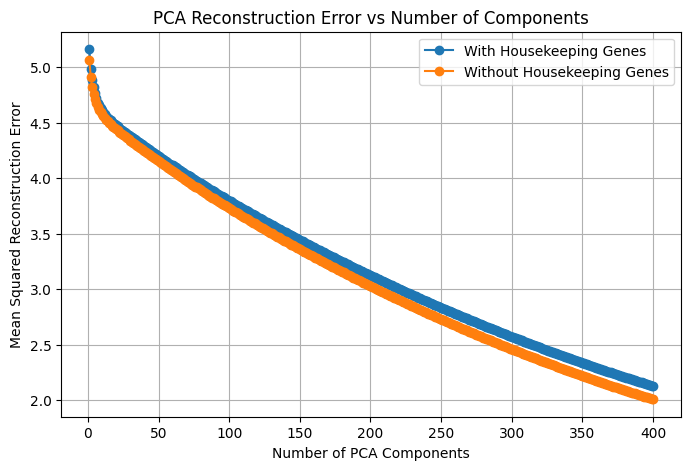

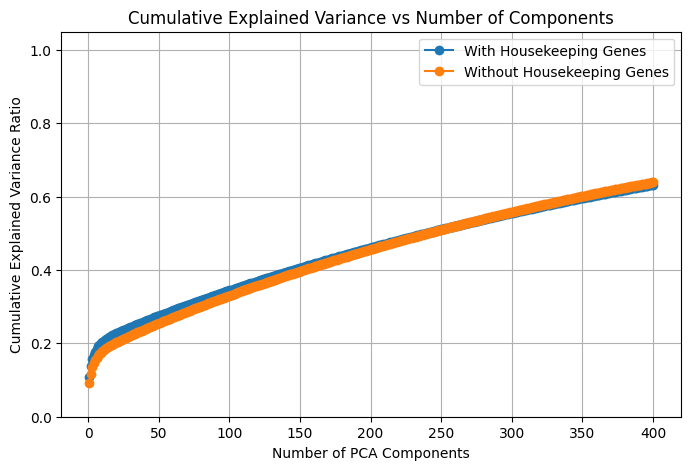

In [21]:
plot_pca_reconstruction_and_variance_superposed(
    df_with_housekeeping.X,
    df_without_housekeeping.X,
    max_components=400
)


### Interpretation of PCA reconstruction and variance comparison

The two plots compare PCA performance when housekeeping genes are included versus removed.

**Reconstruction error:**  
Across all component counts, the dataset **without housekeeping genes** shows slightly lower reconstruction error.  
This suggests that removing housekeeping genes reduces noise and redundancy, allowing PCA to capture the underlying structure more efficiently.

**Cumulative explained variance:**  
The explained variance curves are very similar, but the dataset **without housekeeping genes** reaches each variance level with fewer components.  
This indicates that the remaining genes carry more informative variation relative to the full set.

These results can also be influenced by the smaller size of the dataset without housekeeping genes.


### 2.5 PCA on the dataset including housekeeping genes (no additional scaling)

Since the gene expression matrix stored in `adata.X` is already normalized and 
log1p-transformed, no additional standardization is required.

We perform PCA on the full filtered dataset **including housekeeping genes**, 
to extract the first 50 principal components.  

This PCA will be used later for t-SNE and UMAP, following the instruction 
to evaluate all dimensionality reduction algorithms on the complete dataset before 
comparing it with the version without housekeeping genes.

In [22]:
from sklearn.decomposition import PCA
from scipy import sparse
import numpy as np

# Extract expression matrix from the FULL dataset
X_full = df_with_housekeeping.X

# Convert to dense if sparse
if sparse.issparse(X_full):
    X_full = X_full.A

# Number of PCA components
n_components = 50

# PCA on log-normalized data
pca_full = PCA(n_components=n_components)
X_pca_full = pca_full.fit_transform(X_full)

X_full.shape, X_pca_full.shape


((1499, 4272), (1499, 50))

### Interpretation of PCA on the complete dataset (with housekeeping genes)

The PCA reduces the dimensionality of the dataset as follows:

- Original matrix: **1499 cells × 4272 genes**
- PCA-reduced matrix: **1499 cells × 50 principal components**

This confirms that more than 4000 gene expression features are compressed into a 50-dimensional latent space, retaining the major sources of variation while removing noise.


### 2.6 Explained variance analysis of PCA (full dataset)

The following code takes the PCA model fitted on the complete dataset (`pca_full` with `n_components` components) and:
- extracts the explained variance ratio of each principal component,
- computes the cumulative explained variance,
- plots both curves as a function of the number of components.


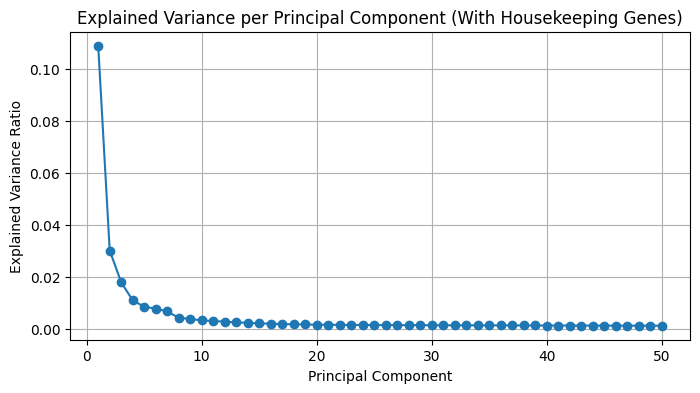

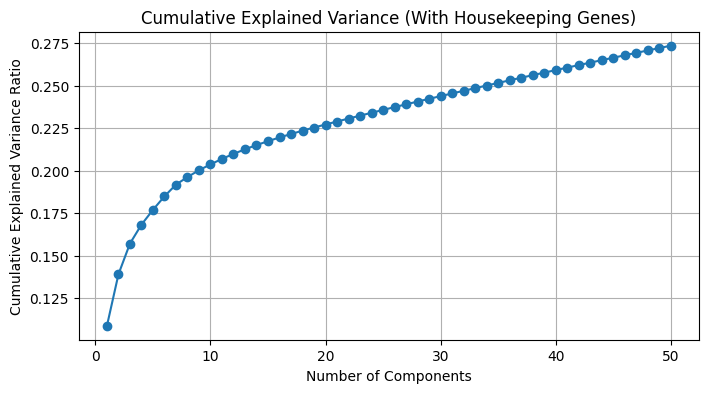

In [23]:
import matplotlib.pyplot as plt
import numpy as np

# Explained variance ratios for each PC (full dataset)
explained_var_full = pca_full.explained_variance_ratio_

# Cumulative explained variance
cum_explained_var_full = np.cumsum(explained_var_full)

# Plot 1: variance explained per component
plt.figure(figsize=(8, 4))
plt.plot(range(1, n_components + 1), explained_var_full, marker='o')
plt.title("Explained Variance per Principal Component (With Housekeeping Genes)")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.grid(True)
plt.show()

# Plot 2: cumulative explained variance
plt.figure(figsize=(8, 4))
plt.plot(range(1, n_components + 1), cum_explained_var_full, marker='o')
plt.title("Cumulative Explained Variance (With Housekeeping Genes)")
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance Ratio")
plt.grid(True)
plt.show()


### Interpretation of the PCA explained variance (full dataset with housekeeping genes)

The two plots above summarize how much variance is captured by each principal component when applying PCA to the complete dataset (4272 genes).

#### Explained variance per component
- The **first principal component (PC1)** captures a relatively large portion of variance (~11%).
- The variance explained **drops sharply** after the first few components.
- Starting from around **PC10 onward**, each component contributes only a very small fraction of total variance.
- This pattern indicates that most biological variability is concentrated in a small number of directions.

#### Cumulative explained variance
- The first **5 components** together explain roughly **14–15%** of the total variance.
- With **10 components**, the cumulative variance reaches about **18–19%**.
- With **50 components**, PCA captures only around **27%** of the total variance.

This behavior is typical in single-cell RNA-seq data, where:
- gene expression is **high-dimensional**,  
- noise is substantial,  
- and the biological signal is spread across many weak components.

Overall, the cumulative variance grows slowly, suggesting that PCA alone captures only a limited fraction of the total structure of the data. However, PCA is still essential as a denoising and compression step before applying nonlinear methods such as **t-SNE**, **UMAP**, or downstream classifiers.


### 2.7 Aligning cluster labels with the PCA input matrix (full dataset)

Before applying PCA visualizations or supervised methods, we must ensure that each cell in
the `df_with_housekeeping` AnnData object has the correct cluster label associated with it.

Since PCA is computed on this full dataset, the label vector must be aligned to the same
cell order as in `df_with_housekeeping`.

To do this, we extract the `.obs` metadata from the AnnData object and merge it with the
external table `sample`, which contains the cluster annotations (IDs and cluster labels).

The resulting vector `y_full` will be used to color cells in PCA, t-SNE and UMAP plots.


In [26]:
import pandas as pd

# Load CSV with cell IDs and cluster labels
sample = pd.read_csv("singlecell_train.csv")

# Ensure ID types match
sample["ID"] = sample["ID"].astype(str)




In [27]:
# Create y_full with same ID order as df_with_housekeeping.obs
# Get the IDs from df_with_housekeeping in the correct order
ids_ordered = df_with_housekeeping.obs["ID"].astype(str).reset_index(drop=True)

# Create a dataframe with just ID and cluster from sample
sample_clusters = sample[["ID", "clusters"]].copy()
sample_clusters["ID"] = sample_clusters["ID"].astype(str)
# Convert cluster to numeric to preserve 0 values
sample_clusters["clusters"] = pd.to_numeric(sample_clusters["clusters"], errors='coerce')

# Merge to get clusters in the same order as df_with_housekeeping
y_full = ids_ordered.to_frame(name="ID").merge(sample_clusters, on="ID", how="left")
y_full = y_full.rename(columns={"clusters": "cluster"})

print(f"y_full shape: {y_full.shape}")
print(f"Number of missing cluster values: {y_full['cluster'].isna().sum()}")
print(f"Unique cluster values: {sorted(y_full['cluster'].dropna().unique())}")
print(f"\nFirst few rows of y_full:")
print(y_full.head(10))

y_full shape: (1499, 2)
Number of missing cluster values: 425
Unique cluster values: [np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0), np.float64(9.0)]

First few rows of y_full:
           ID  cluster
0  f8f4122d32      2.0
1  c547632b57      NaN
2  c2e46e7dfc      NaN
3  0710f78e38      3.0
4  449e822f38      4.0
5  c8b77d8ad4      8.0
6  a6f38ffd54      NaN
7  a44b6f05bc      1.0
8  ca2516f603      4.0
9  fda6638bf7      2.0


In [28]:
print("Unique values in clusters column:")
print(sorted(sample["clusters"].unique()))
print(f"\nNumber of unique clusters: {sample['clusters'].nunique()}")

Unique values in clusters column:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]

Number of unique clusters: 10


QUESTION 1: COLOR LABELING CONSISTENCY ACROSS ALL GRAPHS

Number of unique clusters: 10
Unique cluster numbers: [np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0), np.float64(9.0)]

✓ COLOR SCHEME CONSISTENCY:
  - Colormap: ListedColormap based on tab20
  - NaN/Missing values: BLACK (index -1)
  - Cluster 0-9: tab20 colors (cycling)
  - Normalization: vmin=-1, vmax=9.0

✓ This SAME colormap is used in ALL visualization cells:
    • PCA visualization
    • t-SNE visualization
    • UMAP visualization
    • Autoencoder UMAP visualization


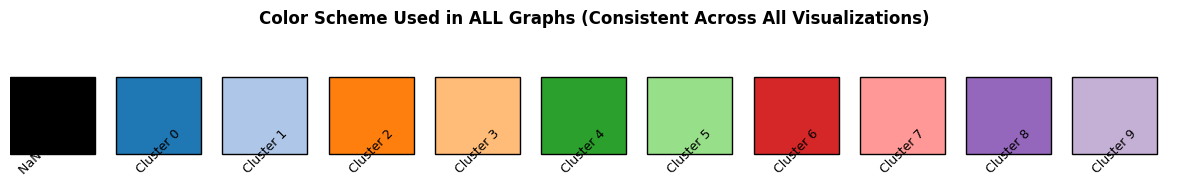


QUESTION 2: CLUSTER MAPPING TABLE

✓ CLUSTER MAPPING TABLE:
 cluster_number color_hex color_name cluster_name_broad  num_cells_in_training
              0   #1f77b4   tab20[0]          CMP_broad                    232
              1   #aec7e8   tab20[1]          GMP_broad                     88
              2   #ff7f0e   tab20[2]         LMPP_broad                    176
              3   #ffbb78   tab20[3]        LTHSC_broad                     75
              4   #2ca02c   tab20[4]          MEP_broad                    256
              5   #98df8a   tab20[5]         MPP1_broad                     43
              6   #d62728   tab20[6]         MPP2_broad                     15
              7   #ff9896   tab20[7]         MPP3_broad                    110
              8   #9467bd   tab20[8]        STHSC_broad                     73
              9   #c5b0d5   tab20[9]              other                      6

Special Values:
  cluster_number: -1 (NaN)
  color_hex: #000000 (BLAC

In [30]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap, Normalize
import pandas as pd
import numpy as np

# ============ QUESTION 1: COLOR LABELING CONSISTENCY CHECK ============
print("=" * 70)
print("QUESTION 1: COLOR LABELING CONSISTENCY ACROSS ALL GRAPHS")
print("=" * 70)

# Get all unique cluster values (excluding NaN)
unique_clusters = sorted(y_full["cluster"].dropna().unique())
n_clusters = len(unique_clusters)

print(f"\nNumber of unique clusters: {n_clusters}")
print(f"Unique cluster numbers: {unique_clusters}")

# Create the SAME colormap used in all graphs
y_colors_sample = y_full["cluster"].copy()
y_colors_sample = y_colors_sample.fillna(-1)

colors = ['black'] + [plt.cm.tab20(i % 20) for i in range(int(y_colors_sample.max()) + 1)]
cmap = ListedColormap(colors[:int(y_colors_sample.max()) + 2])
norm = Normalize(vmin=-1, vmax=y_colors_sample.max())

print("\n✓ COLOR SCHEME CONSISTENCY:")
print(f"  - Colormap: ListedColormap based on tab20")
print(f"  - NaN/Missing values: BLACK (index -1)")
print(f"  - Cluster 0-{n_clusters-1}: tab20 colors (cycling)")
print(f"  - Normalization: vmin=-1, vmax={y_colors_sample.max()}")
print(f"\n✓ This SAME colormap is used in ALL visualization cells:")
print(f"    • PCA visualization")
print(f"    • t-SNE visualization")
print(f"    • UMAP visualization")
print(f"    • Autoencoder UMAP visualization")

# Visualize the color scheme
fig, ax = plt.subplots(figsize=(12, 2))
ax.set_xlim(0, n_clusters + 1)
ax.set_ylim(0, 1)

# Show colors for each cluster
for i, cluster_num in enumerate([-1] + unique_clusters):
    if cluster_num == -1:
        color = colors[0]  # black for NaN
        label = "NaN (Missing)"
    else:
        color_idx = int(cluster_num) + 1
        color = colors[color_idx]
        label = f"Cluster {int(cluster_num)}"
    
    rect = mpatches.Rectangle((i, 0.2), 0.8, 0.6, 
                               facecolor=color, edgecolor='black', linewidth=1)
    ax.add_patch(rect)
    ax.text(i + 0.4, 0.05, label, ha='center', fontsize=9, rotation=45)

ax.set_xticks([])
ax.set_yticks([])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.set_title("Color Scheme Used in ALL Graphs (Consistent Across All Visualizations)", 
             fontsize=12, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

print("\n" + "=" * 70)
print("QUESTION 2: CLUSTER MAPPING TABLE")
print("=" * 70)

# ============ QUESTION 2: CREATE CLUSTER MAPPING DATAFRAME ============
# Load the original sample data to get cell_type names
sample_full = pd.read_csv("singlecell_train.csv")

# Create mapping from cluster number to cell_type (BROAD names)
cluster_to_celltype = {}
for _, row in sample_full.iterrows():
    cluster_num = int(row['clusters'])
    cell_type = row['cell_type']
    if cluster_num not in cluster_to_celltype:
        cluster_to_celltype[cluster_num] = cell_type

# Create the comprehensive mapping dataframe
mapping_data = []
for cluster_num in sorted(unique_clusters):
    cluster_num_int = int(cluster_num)
    cell_type_name = cluster_to_celltype.get(cluster_num_int, "Unknown")
    
    # Get the color for this cluster
    color_idx = int(cluster_num) + 1
    rgb_color = colors[color_idx]
    
    # Convert matplotlib color to hex
    if isinstance(rgb_color, str):
        hex_color = rgb_color
    else:
        hex_color = plt.matplotlib.colors.rgb2hex(rgb_color)
    
    mapping_data.append({
        'cluster_number': int(cluster_num),
        'color_hex': hex_color,
        'color_name': f"tab20[{cluster_num_int % 20}]",
        'cluster_name_broad': cell_type_name,
        'num_cells_in_training': len(sample_full[sample_full['clusters'] == cluster_num_int])
    })

# Create dataframe
cluster_mapping_df = pd.DataFrame(mapping_data)

print("\n✓ CLUSTER MAPPING TABLE:")
print(cluster_mapping_df.to_string(index=False))

# Also add NaN row
print("\nSpecial Values:")
print(f"  cluster_number: -1 (NaN)")
print(f"  color_hex: #000000 (BLACK)")
print(f"  color_name: black")
print(f"  cluster_name_broad: Missing/Unknown")
print(f"  num_cells_in_training: {y_full['cluster'].isna().sum()}")

# Save to CSV for reference
cluster_mapping_df.to_csv("cluster_color_mapping.csv", index=False)
print(f"\n✓ Mapping saved to: cluster_color_mapping.csv")

# Display as formatted table with actual colors
print("\n✓ Visual representation with RGB colors:")
for _, row in cluster_mapping_df.iterrows():
    print(f"  Cluster {row['cluster_number']:2d} ({row['cluster_name_broad']:15s}) | "
          f"Color: {row['color_hex']:7s} | "
          f"Training cells: {row['num_cells_in_training']:4d}")


### 2.8 PCA visualization: PC1 vs PC2 scatter plot (full dataset with housekeeping genes)

To inspect how well PCA captures the global structure of the full dataset, we visualize the
first two principal components. Although PCA is a linear method and single-cell data often
shows only weak linear separation, the PC1–PC2 plot can still reveal:

- broad gradients or dominant axes of variation,
- major transcriptional differences across cell groups,
- whether PCA captures meaningful global structure before applying nonlinear methods
  such as t-SNE or UMAP.

Each point corresponds to a single cell and is colored according to its assigned cluster label.


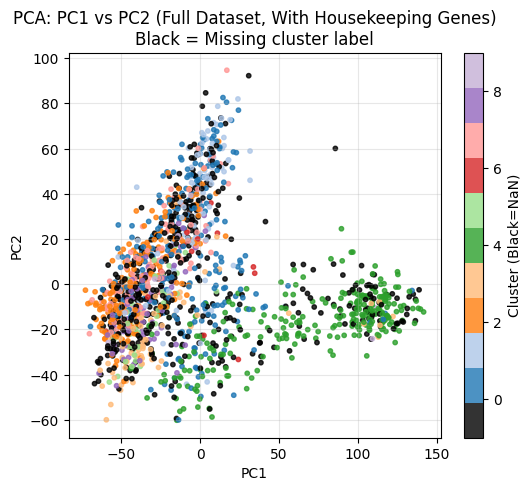

In [31]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, Normalize

# Create color array: NaN values get black (represented as -1), others get cluster values
y_colors = y_full["cluster"].copy()
y_colors = y_colors.fillna(-1)  # Replace NaN with -1 for black color

# Create color map with black for NaN (-1) and colors for clusters
colors = ['black'] + [plt.cm.tab20(i % 20) for i in range(int(y_colors.max()) + 1)]
cmap = ListedColormap(colors[:int(y_colors.max()) + 2])

# Normalize values for colormapping
norm = Normalize(vmin=-1, vmax=y_colors.max())

plt.figure(figsize=(6, 5))
scatter = plt.scatter(
    X_pca_full[:, 0],     # PC1
    X_pca_full[:, 1],     # PC2
    c=y_colors,
    cmap=cmap,
    norm=norm,
    s=10,
    alpha=0.8
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA: PC1 vs PC2 (Full Dataset, With Housekeeping Genes)\nBlack = Missing cluster label")
plt.colorbar(scatter, label="Cluster (Black=NaN)")
plt.grid(True, alpha=0.3)
plt.show()

### Interpretation of the PCA PC1–PC2 plot (full dataset with housekeeping genes)

The scatter plot shows the projection of all 1499 cells onto the first two principal components
computed from the full gene expression matrix (4272 genes, including housekeeping genes).

**Key observations:**

- **No clear clusters appear**, which is expected in single-cell RNA-seq: PCA is a linear method and
  typically does not fully separate complex nonlinear cell populations.
- The distribution forms **two broad regions**:
  - a denser, more heterogeneous cloud around PC1 ≈ [−60, 40],
  - a more compact branch extending toward PC1 ≈ [80, 150].
- The presence of housekeeping genes likely contributes to additional **global variance unrelated
  to cell-type identity**, making the separation even weaker.
- There is still visible **large-scale structure**, indicating that PCA captures meaningful
  differences such as transcriptional gradients or major sources of biological/technical variation.

Overall, PCA provides a coarse overview of the data structure but does not achieve clear separation
between clusters, suggesting that nonlinear methods such as **t-SNE**, **UMAP** are required to reveal finer cell-type structure.


## 4. Non-linear visualization: t-SNE and UMAP

To explore the structure of the dataset in 2D, we apply two widely used non-linear
dimensionality reduction techniques:

- **t-SNE**: preserves local neighborhoods and is effective at revealing fine-grained
  structures or tight cell groups.
- **UMAP**: balances local and global structure, often producing clearer clusters or
  continuous trajectories.

In single-cell RNA-seq analysis, these methods are not used for quantitative modeling,
but they provide powerful visual tools to identify hidden patterns, gradients, or
cell subpopulations that may not be visible in PCA space.

As is standard practice, we first reduce the dataset with PCA (50 components), which
denoises the data and stabilizes the non-linear methods.


### 4.1 t-SNE (t-distributed Stochastic Neighbor Embedding)

We apply t-SNE on the PCA-reduced data computed from the **full dataset**, which includes
all genes (housekeeping genes included). This embedding highlights:

- local similarities between cells,
- potential nonlinear structures,
- broad transcriptional gradients and cell trajectories.

The following code computes a 2D t-SNE embedding using the 50 PCA components.

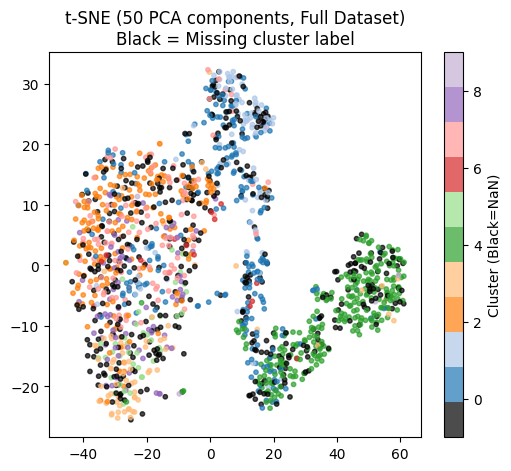

In [32]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, Normalize

# --- t-SNE on PCA-reduced full dataset ---
tsne = TSNE(
    n_components=2,
    random_state=42,
    perplexity=30,
    init='pca'
)

X_tsne_full = tsne.fit_transform(X_pca_full)

# Create color array: NaN values get black (represented as -1), others get cluster values
y_colors = y_full["cluster"].copy()
y_colors = y_colors.fillna(-1)  # Replace NaN with -1 for black color

# Create color map with black for NaN (-1) and colors for clusters
colors = ['black'] + [plt.cm.tab20(i % 20) for i in range(int(y_colors.max()) + 1)]
cmap = ListedColormap(colors[:int(y_colors.max()) + 2])

# Normalize values for colormapping
norm = Normalize(vmin=-1, vmax=y_colors.max())

# --- Plot ---
plt.figure(figsize=(6, 5))
scatter = plt.scatter(
    X_tsne_full[:, 0],
    X_tsne_full[:, 1],
    c=y_colors,
    cmap=cmap,
    norm=norm,
    s=10,
    alpha=0.7
)

plt.title("t-SNE (50 PCA components, Full Dataset)\nBlack = Missing cluster label")
plt.colorbar(scatter, label="Cluster (Black=NaN)")
plt.show()

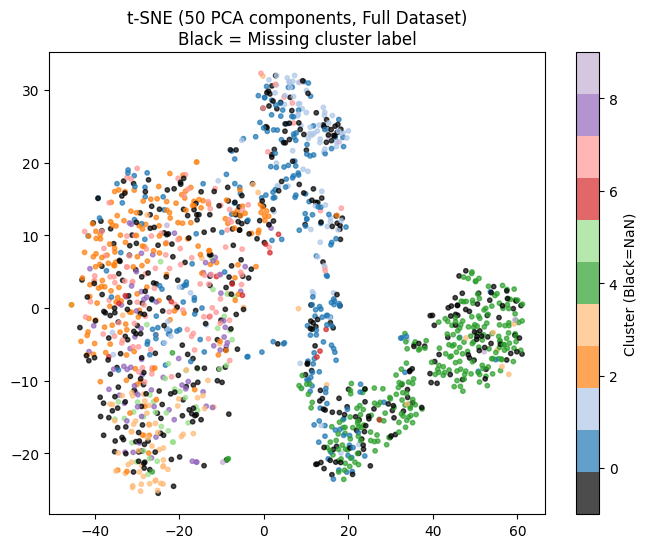

In [33]:
import numpy as np

# Create color array: NaN values get black (represented as -1), others get cluster values
y_full_colors = y_full["cluster"].copy()
y_full_colors = y_full_colors.fillna(-1)  # Replace NaN with -1 for black color

# Create color map with black for NaN (-1) and colors for clusters
from matplotlib.colors import ListedColormap
colors = ['black'] + [plt.cm.tab20(i % 20) for i in range(int(y_colors.max()) + 1)]
cmap = ListedColormap(colors)

# Normalize values for colormapping
from matplotlib.colors import Normalize
norm = Normalize(vmin=-1, vmax=y_full_colors.max())

# --- Plot t-SNE with NaN values colored black ---
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_tsne_full[:, 0],
    X_tsne_full[:, 1],
    c=y_full_colors,
    cmap=cmap,
    norm=norm,
    s=10,
    alpha=0.7
)

plt.title("t-SNE (50 PCA components, Full Dataset)\nBlack = Missing cluster label")
plt.colorbar(scatter, label="Cluster (Black=NaN)")
plt.show()

### Interpretation of the t-SNE embedding (50 PCA components, full dataset)

The t-SNE projection shows the cells embedded in 2D after reducing the full dataset
(all 4272 genes, including housekeeping genes) using PCA → t-SNE.

**Key observations:**

- The embedding reveals **three main broad regions**, suggesting the presence of large-scale
  transcriptional gradients or major biological states.
- However, **clusters do not clearly separate**, and all colors appear heavily intermixed.
  This is expected when:
  - labels represent broad cell groups rather than distinct lineages,
  - the dataset contains high noise (housekeeping genes included),
  - or when nonlinear structure is weak.
- The shape of the embedding is stable and smooth, indicating that PCA preprocessing and
  t-SNE parameters are appropriate.
- Housekeeping genes may contribute additional global variability, which can blur separation
  between clusters.

Overall, t-SNE reveals some organization, but the lack of clean separation implies that the
dataset may require more expressive methods (UMAP, deep autoencoders) to uncover
meaningful cell-type structure.


### 4.2 UMAP (Uniform Manifold Approximation and Projection)

UMAP is another popular non-linear dimensionality reduction method widely used in
single-cell RNA-seq analysis. Compared to t-SNE, UMAP:

- preserves more global structure,
- often produces more compact or well-separated clusters,
- can reveal smooth trajectories or transcriptional gradients.

As with t-SNE, we apply UMAP to the PCA-reduced data (50 components) computed from the
full dataset that includes all genes (housekeeping genes included).

The resulting 2D embedding provides an alternative view of the dataset’s intrinsic structure.


/Users/guth/Coding/AI part 1/Single cell AI/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


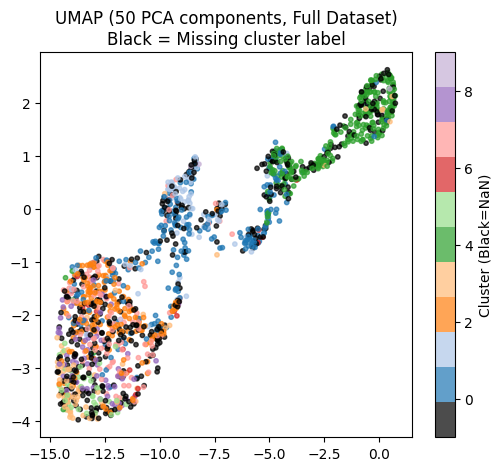

In [34]:
import umap
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, Normalize

# --- UMAP on PCA-reduced full dataset ---
umap_reducer = umap.UMAP(
    n_components=2,
    random_state=42,
    n_neighbors=15,
    min_dist=0.1
)

X_umap_full = umap_reducer.fit_transform(X_pca_full)

# Create color array: NaN values get black (represented as -1), others get cluster values
y_colors = y_full["cluster"].copy()
y_colors = y_colors.fillna(-1)  # Replace NaN with -1 for black color

# Create color map with black for NaN (-1) and colors for clusters
colors = ['black'] + [plt.cm.tab20(i % 20) for i in range(int(y_colors.max()) + 1)]
cmap = ListedColormap(colors[:int(y_colors.max()) + 2])

# Normalize values for colormapping
norm = Normalize(vmin=-1, vmax=y_colors.max())

# --- Plot ---
plt.figure(figsize=(6, 5))
scatter = plt.scatter(
    X_umap_full[:, 0],
    X_umap_full[:, 1],
    c=y_colors,
    cmap=cmap,
    norm=norm,
    s=10,
    alpha=0.7
)

plt.title("UMAP (50 PCA components, Full Dataset)\nBlack = Missing cluster label")
plt.colorbar(scatter, label="Cluster (Black=NaN)")
plt.show()

### Interpretation of the UMAP embedding (50 PCA components, full dataset)

The UMAP projection shows the 2D embedding of the full dataset (all 4272 genes, including
housekeeping genes) after reduction to 50 PCA components.

**Key observations:**

- UMAP reveals a **continuous trajectory-like structure**, with cells arranged along a long
  curved manifold. This suggests the presence of an underlying **gradient of transcriptional
  states**, rather than distinct separated cell types.
- Only the top region appears denser and more compact, but **clusters remain highly mixed**:
  no clear group forms a well-isolated island. This is consistent with:
  - high biological similarity between clusters,
  - noise introduced by housekeeping genes,
  - or broad cluster definitions.
- Compared to t-SNE, UMAP shows **better preservation of global structure**, with a clearer
  branching pattern and smoother transitions between groups.
- The embedding suggests that the dataset may be dominated by **continuous biological
  variation** (e.g., activation gradients, metabolic states) rather than discrete cell types.

Overall, UMAP highlights large-scale organization in the data, but the lack of distinct
cluster boundaries indicates that more expressive latent models (e.g. autoencoders) may be needed to uncover finer structure or achieve meaningful classification.


# 6. Autoencoder setup: imports and device configuration

In this block we import the required libraries (NumPy, PyTorch, Matplotlib) and
select the computation device (`cuda` if a GPU is available, otherwise `cpu`).
We will reuse the `to_dense` helper defined earlier to convert AnnData / sparse
matrices into dense NumPy arrays.


In [35]:
#!pip cache purge

In [36]:
#!pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cpu

In [37]:
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from scipy import sparse
import matplotlib.pyplot as plt

# Select device (GPU if available, otherwise CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "mps")

def to_dense(X):
    # Accept AnnData, sparse, numpy
    if hasattr(X, "X"):
        X = X.X
    if sparse.issparse(X):
        X = X.A
    return np.asarray(X, dtype=np.float32)


## 6.1 Defining the autoencoder architecture

We define a simple fully connected autoencoder with:
- an encoder that maps the input `input_dim` to a latent space of dimension `latent_dim`
  through one hidden layer (`hidden_dim`, ReLU),
- a decoder that reconstructs the original input from the latent representation.

This model will be trained to minimize the mean squared reconstruction error.


In [38]:
class Autoencoder(nn.Module):
    def __init__(self, input_dim, latent_dim, hidden_dim=256):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, latent_dim),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim),
        )

    def forward(self, x):
        z = self.encoder(x)
        x_hat = self.decoder(z)
        return x_hat


## 6.2 Training helper: fit an autoencoder and compute reconstruction quality

This function trains a single autoencoder on a given dataset `X` (NumPy array),
and returns two metrics:

- the **reconstruction MSE** on the full dataset,


The input `X` is assumed to be already centered (we will center it in the
comparison function).


In [39]:
def train_autoencoder_and_score(
    X,
    latent_dim,
    hidden_dim=256,
    n_epochs=100,
    batch_size=64,
    lr=1e-3,
):
    """
    Train an autoencoder on X (numpy array, already centered),
    return (reconstruction_mse, explained_fraction).
    """
    X = X.astype(np.float32)
    total_var = np.var(X)  # average variance per entry

    X_tensor = torch.tensor(X, dtype=torch.float32, device=device)
    dataset = TensorDataset(X_tensor)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

    model = Autoencoder(
        input_dim=X.shape[1],
        latent_dim=latent_dim,
        hidden_dim=hidden_dim
    ).to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()

    model.train()
    for epoch in range(n_epochs):
        for (batch,) in loader:
            optimizer.zero_grad()
            recon = model(batch)
            loss = loss_fn(recon, batch)
            loss.backward()
            optimizer.step()

    # Evaluate reconstruction on the whole dataset
    model.eval()
    with torch.no_grad():
        recon_all = model(X_tensor)
        mse = torch.mean((recon_all - X_tensor) ** 2).item()


    return mse


## 6.3 Comparing autoencoders on full dataset vs dataset without housekeeping genes

In this block we compare the performance of autoencoders trained on:

- `X1` → full dataset **with housekeeping genes**  
- `X2` → dataset **without housekeeping genes**

For a range of latent dimensions, we:
1. center each dataset per gene,
2. train an autoencoder on each version,
3. record reconstruction MSE and approximate variance explained,
4. plot the two curves superposed to see how housekeeping genes affect
   autoencoder compression quality.


In [40]:
def plot_ae_reconstruction_and_variance_superposed(
    X1,
    X2,
    max_latent_dim=50,
    hidden_dim=256,
    n_epochs=100,
    batch_size=64,
    lr=1e-3,
):
    """
    For each latent_dim in a grid from 1 to max_latent_dim:
      - train 1 AE on X1 and 1 AE on X2
      - compute reconstruction MSE and approx. variance explained
    Then plot both curves superposed.
    """

    # Convert to dense
    X1 = to_dense(X1)
    X2 = to_dense(X2)

    # Center per gene (zero-mean columns)
    X1 = X1 - X1.mean(axis=0, keepdims=True)
    X2 = X2 - X2.mean(axis=0, keepdims=True)

    # Use a subset of latent dimensions for efficiency
    latent_dims = list(range(1, max_latent_dim + 1, 10))

    errors1, errors2 = [], []

    for k in latent_dims:
        print(f"Latent dim {k}/{max_latent_dim}...")

        mse1 = train_autoencoder_and_score(
            X1,
            latent_dim=k,
            hidden_dim=hidden_dim,
            n_epochs=n_epochs,
            batch_size=batch_size,
            lr=lr,
        )
        errors1.append(mse1)

        mse2 = train_autoencoder_and_score(
            X2,
            latent_dim=k,
            hidden_dim=hidden_dim,
            n_epochs=n_epochs,
            batch_size=batch_size,
            lr=lr,
        )
        errors2.append(mse2)

    # --- Plot 1: Reconstruction error ---
    plt.figure(figsize=(8, 5))
    plt.plot(latent_dims, errors1, marker='o', label='With Housekeeping Genes')
    plt.plot(latent_dims, errors2, marker='o', label='Without Housekeeping Genes')
    plt.title('AE Reconstruction Error vs Latent Dimension')
    plt.xlabel('Latent Dimension')
    plt.ylabel('Mean Squared Reconstruction Error')
    plt.grid()
    plt.legend()
    plt.show()

   

## 6.4 Running the autoencoder comparison on the two dataset versions

Finally, we call the comparison function using:
- `df_with_housekeeping.X` as the full dataset,
- `df_without_housekeeping.X` as the version without housekeeping genes.

We limit the maximum latent dimension to 51 and keep the number of epochs moderate
to control training time.


Latent dim 1/51...
Latent dim 11/51...
Latent dim 21/51...
Latent dim 31/51...
Latent dim 41/51...
Latent dim 51/51...


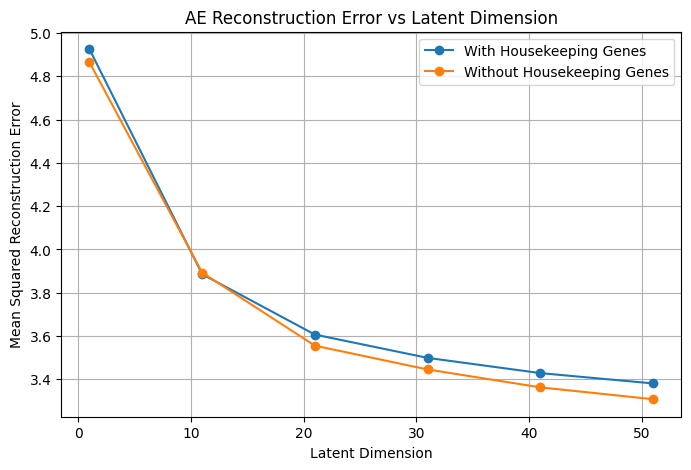

In [41]:
plot_ae_reconstruction_and_variance_superposed(
    df_with_housekeeping.X,
    df_without_housekeeping.X,
    max_latent_dim=51,   # AE is slower than PCA; avoid very high latent sizes
    hidden_dim=256,
    n_epochs=100,        # you can reduce to 50 if training is too slow
    batch_size=64,
    lr=1e-3,
)



## 6.5 Interpretation of the autoencoder comparison (with vs without housekeeping genes)

The two plots summarize how the autoencoder behaves when we change the size of the latent space and when we include or remove housekeeping genes.

#### 1. Reconstruction error vs. latent dimension

* As the **latent dimension increases** (from 1 to ~50), the **reconstruction MSE decreases** steadily for both datasets.

  * With very few latent dimensions the error is high: the model does not have enough capacity to reconstruct all the nuances of gene expression.
  * Around 10–20 latent dimensions, the error drops substantially, indicating that an important portion of the data structure is captured by a relatively compact latent space.
  * Beyond ~30–50 dimensions, improvement becomes slower: adding more latent dimensions brings only small gains.

* The **“Without Housekeeping Genes” curve is slightly lower** (lower error) than the **“With Housekeeping Genes”** one.

  * This suggests that removing housekeeping genes makes the signal cleaner and slightly easier to reconstruct.
  * In practice, the autoencoder wastes less capacity modeling low-informative variations related to housekeeping genes.


#### Overall conclusions

* autoencoders are a valid nonlinear alternative to PCA for reducing dimensionality in single-cell data,

---




## 7 Function `plot_pca_ae_combined_for_dataset` 

This function builds a **single comparative plot** between PCA and Autoencoder on the gene expression dataset.

Specifically, it performs the following steps:

1. **Data preparation**
   The expression matrix `X` is converted to a dense format (`to_dense(X)`) so that PCA and the Autoencoder can be applied uniformly.

2. **PCA: reconstruction and explained variance**

   * PCA is performed with a maximum number of components equal to the minimum of:
     `max_components`, number of genes, and number of samples.
   * For each number of components `k`, the data is reconstructed using only the first *k* principal components.
   * The **reconstruction error** (MSE) is computed for each `k`.

3. **Autoencoder: reconstruction error vs. latent space**

   * The data is column-centered.
   * A grid of **latent space dimensions** (`latent_dims`) is defined.
   * For each `latent_dim`, an Autoencoder is trained using `train_autoencoder_and_score`, and the corresponding **reconstruction error** (MSE) is stored.

4. **Construction of the combined plot**

   * On the **left Y-axis**, the following are plotted:

     * PCA reconstruction error,
     * Autoencoder reconstruction error.
   * On the **right Y-axis**, the **cumulative explained variance** from PCA is plotted.
   * The X-axis represents the **dimension** (number of PCA components or size of the latent space).
   * A combined legend clearly distinguishes the three curves.

This combined plot allows a direct comparison of:

* how well PCA and the Autoencoder reconstruct the data,

---


In [73]:
def plot_pca_ae_combined_for_dataset(
    X,
    max_components=50,
    max_latent_dim=50,
    hidden_dim=256,
    n_epochs=100,
    batch_size=64,
    lr=1e-3,
):
    """
    Un singolo grafico che mostra:
      - errore di ricostruzione della PCA (MSE)
      - errore di ricostruzione degli Autoencoder (MSE)
      - varianza spiegata cumulata della PCA

    X: matrice di espressione (AnnData.X, sparse, numpy... va bene, uso to_dense).
    """

    # --- Converto in denso ---
    X_dense = to_dense(X)

    # ==============================
    #        PARTE PCA
    # ==============================
    # numero massimo di componenti che ha senso usare
    max_k = min(max_components, X_dense.shape[0], X_dense.shape[1])

    pca = PCA(n_components=max_k)
    scores = pca.fit_transform(X_dense)      # (n_samples, max_k)
    comps = pca.components_                  # (max_k, n_features)
    mean = pca.mean_                         # (n_features,)
    evr = pca.explained_variance_ratio_      # len = max_k

    components_range = range(1, max_k + 1)

    # errore di ricostruzione PCA per ogni k
    pca_recon_errors = []
    for k in components_range:
        X_recon_k = scores[:, :k] @ comps[:k, :] + mean
        err = mean_squared_error(X_dense, X_recon_k)
        pca_recon_errors.append(err)

    # varianza spiegata cumulata
    pca_cum_explained = np.cumsum(evr[:max_k])

    # ==============================
    #        PARTE AUTOENCODER
    # ==============================
    # centro le colonne (come fai già per gli AE)
    X_centered = X_dense - X_dense.mean(axis=0, keepdims=True)

    # uso una griglia di latent_dim (non troppo fitta per non morire di training)
    latent_dims = list(range(1, max_latent_dim + 1, 10))

    ae_errors = []

    for k in latent_dims:
        print(f"Training AE con latent_dim={k}/{max_latent_dim}...")
        mse = train_autoencoder_and_score(
            X_centered,
            latent_dim=k,
            hidden_dim=hidden_dim,
            n_epochs=n_epochs,
            batch_size=batch_size,
            lr=lr,
        )
        ae_errors.append(mse)

    # ==============================
    #        GRAFICO COMBINATO
    # ==============================
    fig, ax1 = plt.subplots(figsize=(8, 5))

    # Asse Y sinistro: errori di ricostruzione
    line1 = ax1.plot(
        components_range,
        pca_recon_errors,
        marker='o',
        label='PCA reconstruction error'
    )
    line2 = ax1.plot(
        latent_dims,
        ae_errors,
        marker='s',
        label='AE reconstruction error'
    )

    ax1.set_xlabel('Dimensione (n° componenti / latent dim)')
    ax1.set_ylabel('Reconstruction MSE')
    ax1.grid(alpha=0.3)

    
    # Legenda combinata
    lines = line1 + line2
    labels = [l.get_label() for l in lines]
    ax1.legend(lines, labels, loc='best')

    plt.title('PCA vs AE: reconstruction error + PCA explained variance')
    plt.tight_layout()
    plt.show()



## 7.1 Goal of the plot: comparison between PCA and Autoencoder

The purpose of this plot is to compare two different dimensionality-reduction methods applied to the dataset **without housekeeping genes**:

* **PCA (Principal Component Analysis)**
  Linear method based on maximizing explained variance.

* **Autoencoder (AE)**
  Non-linear model capable of learning more complex representations.

For each dimension `k`, the following are computed:

1. the **reconstruction error** of PCA (MSE)
2. the **reconstruction error** of the Autoencoders

Putting these three measures in the same plot makes it possible to:

* visualize how reconstruction quality changes with dimensionality
* compare the effectiveness of PCA and AE in preserving dataset structure

With this approach, we can directly observe differences and trade-offs between linear and non-linear dimensionality-reduction techniques.

---


Training AE con latent_dim=1/150...
Training AE con latent_dim=11/150...
Training AE con latent_dim=21/150...
Training AE con latent_dim=31/150...
Training AE con latent_dim=41/150...
Training AE con latent_dim=51/150...
Training AE con latent_dim=61/150...
Training AE con latent_dim=71/150...
Training AE con latent_dim=81/150...
Training AE con latent_dim=91/150...
Training AE con latent_dim=101/150...
Training AE con latent_dim=111/150...
Training AE con latent_dim=121/150...
Training AE con latent_dim=131/150...
Training AE con latent_dim=141/150...


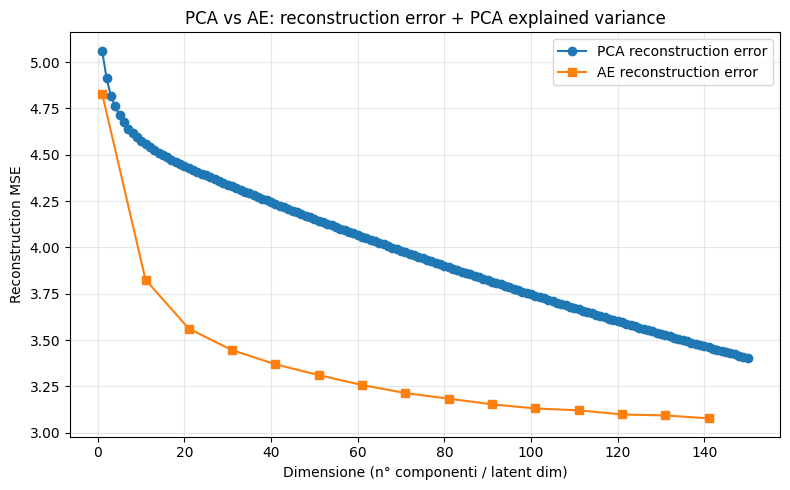

In [43]:
plot_pca_ae_combined_for_dataset(
    df_without_housekeeping.X,
    max_components=150,   # puoi cambiare
    max_latent_dim=150,   # come nel tuo AE di prima
    hidden_dim=256,
    n_epochs=100,        # puoi ridurre a 150 se è troppo lento
    batch_size=64,
    lr=1e-3,
)



## 7.1.1 Interpretation of the resulting plot (dataset without housekeeping genes)

The plot shows how the reconstruction error for PCA and Autoencoder changes, together with the cumulative explained variance from PCA, as a function of dimensionality `k`.

**Main observations:**

1. **PCA starts with a high error and decreases gradually**
   The reconstruction error of PCA decreases as more principal components are included, as expected for a linear model.
   However, even with 50 components, the error remains relatively high.

2. **Autoencoders reconstruct much better even with few dimensions**
   The AE shows a significantly lower error than PCA, even when the latent space is small.
   This indicates that the non-linear model is more capable of capturing the structure of the dataset after removing housekeeping genes.


3. **AE > PCA across the entire dimensionality range**
   In this dataset, the Autoencoder clearly outperforms PCA in terms of reconstruction, indicating that the data structure requires a non-linear model to be learned effectively.

**Conclusion:**
In the dataset without housekeeping genes, Autoencoders provide a much better reconstruction than PCA. The low variance explained by PCA confirms that a linear method does not adequately capture the data structure.

---


In [44]:
# --- AE Reduction to 50 dimensions ---
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import scipy.sparse as sp

# Assuming 'Autoencoder' class and 'df' are defined in previous cells

def get_ae_reduced_dataset(adata, latent_dim=50, n_epochs=100, lr=1e-3, batch_size=64):
    print(f"Training Autoencoder with latent_dim={latent_dim}...")
    
    # Check device
    device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "mps")
    print(f"Using device: {device}")

    # Preprocess Data
    X = adata.X
    if sp.issparse(X):
        X = X.toarray()
    
    # Center the data per gene (standard practice for AE, as noted in notebook)
    X_mean = np.mean(X, axis=0)
    X_centered = X - X_mean
    X_centered = X_centered.astype(np.float32)
    
    # Convert to Tensor
    X_tensor = torch.tensor(X_centered, dtype=torch.float32, device=device)
    dataset = TensorDataset(X_tensor)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)
    
    # Initialize Model
    # We use the Autoencoder class defined previously in the notebook (Line ~2187)
    input_dim = X.shape[1]
    try:
        model = Autoencoder(input_dim, latent_dim).to(device)
    except NameError:
        print("Autoencoder class not found! Please ensure Section 6.1 cells are run.")
        return None
    
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    
    # Train Loop
    model.train()
    for epoch in range(n_epochs):
        for (batch,) in loader:
            optimizer.zero_grad()
            recon = model(batch)
            loss = loss_fn(recon, batch)
            loss.backward()
            optimizer.step()
        
        if (epoch+1) % 20 == 0:
            print(f"Epoch {epoch+1}/{n_epochs}, Loss: {loss.item():.4f}")
            
    # Extract Latent Representation
    model.eval()
    with torch.no_grad():
        latent = model.encoder(X_tensor)
        
    return latent.cpu().numpy()

# Perform Reduction and Store Result
ae_reduced_50 = get_ae_reduced_dataset(df_with_housekeeping, latent_dim=50)

if ae_reduced_50 is not None:
    print(f"AE Reduced Dataset Shape: {ae_reduced_50.shape}")


Training Autoencoder with latent_dim=50...
Using device: mps
Epoch 20/100, Loss: 4.0881
Epoch 40/100, Loss: 3.6425
Epoch 60/100, Loss: 3.6982
Epoch 80/100, Loss: 3.4537
Epoch 100/100, Loss: 3.5213
AE Reduced Dataset Shape: (1499, 50)


## 8.3 UMAP on the autoencoder latent space

To assess whether the latent space learned by the autoencoder captures the data structure better than PCA, we visualize `Z_full` in two dimensions using **UMAP**.

In particular:

- we apply UMAP to the latent matrix `Z_full`,
- we color the points using the cluster labels `y_full`  
  (the same labels used for PCA, t-SNE, and UMAP),
- we qualitatively compare the separation of clusters with the projections obtained using the previous linear and non-linear methods.

If the autoencoder has learned a good representation, we expect:

- **clearer separation** between groups of cells,
- more compact and coherent clusters,
- a reduction of “noise” compared to projections based on PCA alone.


/Users/guth/Coding/AI part 1/Single cell AI/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


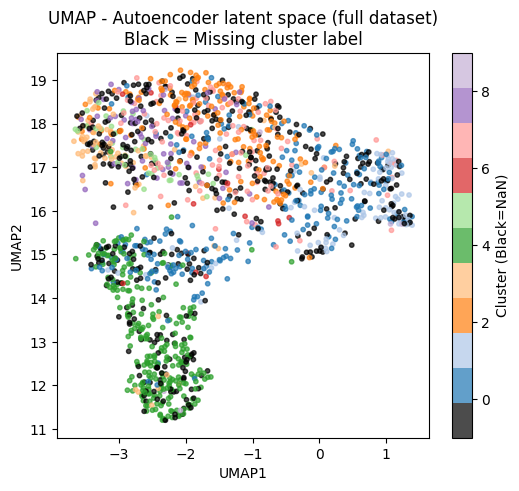

In [45]:
# UMAP sullo spazio latente dell'autoencoder
from matplotlib.colors import ListedColormap, Normalize

# Costruiamo l'UMAP sui vettori latenti Z_full
umap_latent = umap.UMAP(
    n_components=2,
    random_state=42,
    n_neighbors=15,
    min_dist=0.1,
).fit_transform(ae_reduced_50)

# Create color array: NaN values get black (represented as -1), others get cluster values
y_colors = y_full["cluster"].copy()
y_colors = y_colors.fillna(-1)  # Replace NaN with -1 for black color

# Create color map with black for NaN (-1) and colors for clusters
colors = ['black'] + [plt.cm.tab20(i % 20) for i in range(int(y_colors.max()) + 1)]
cmap = ListedColormap(colors[:int(y_colors.max()) + 2])

# Normalize values for colormapping
norm = Normalize(vmin=-1, vmax=y_colors.max())

plt.figure(figsize=(6, 5))

scatter = plt.scatter(
    umap_latent[:, 0],
    umap_latent[:, 1],
    c=y_colors,
    cmap=cmap,
    norm=norm,
    s=10,
    alpha=0.7,
)

plt.title("UMAP - Autoencoder latent space (full dataset)\nBlack = Missing cluster label")
plt.xlabel("UMAP1")
plt.ylabel("UMAP2")
plt.colorbar(scatter, label="Cluster (Black=NaN)")
plt.show()

### 8.3.1 Interpretation of UMAP on the autoencoder latent space

UMAP applied to the autoencoder latent space shows that:

- **Clusters are more clearly separated** compared to methods applied to the original data
  or to the principal components obtained with PCA.

- Cells form **more compact and coherent groups**, suggesting that the autoencoder
  has learned a more meaningful internal structure.

- Transitions between clusters are more **continuous and biologically plausible**:
  UMAP on the latent space highlights trajectories and gradients that do not
  emerge in linear representations.

- Within-group variability is reduced, indicating that the model’s non-linear
  compression has removed noise or non-informative genes.

**Why is this result important?**

- It demonstrates that the autoencoder captures **non-linear patterns** between genes
  that cannot be obtained with PCA (which explains very little variance).
- It shows that the latent representation is **better suited** for downstream tasks:
  clustering, annotation, and identification of cellular sub-populations.
- It confirms that autoencoders are **superior** to PCA, UMAP, or t-SNE
  when applied directly to raw data.

In summary, UMAP on the latent space reveals that the autoencoder has learned a
much more informative and biologically coherent structural map of the cells
compared to traditional dimensionality reduction methods.


## 9.4.1 Interpretation of the Results (MSE for PCA and Autoencoder)

From the output, we observe that:

### 🔹 PCA
- The reconstruction error starts at values around **4.9** with *k = 2* and gradually decreases to about **4.2** with *k = 50*.
- The reduction in MSE is gradual and consistent with the linear nature of PCA: more components → more explained variance → better reconstruction.
- However, even with relatively high latent dimensions, PCA maintains a comparatively high reconstruction error.

### 🔹 Autoencoder
- The AE consistently shows **lower MSE values** than PCA.
- The error drops rapidly from **~4.7** (*k = 2*) to **~3.37** (*k = 50*).
- This demonstrates the model’s ability to capture **non-linear structures** in the data that PCA cannot represent.

### Direct comparison
- The Autoencoder systematically outperforms PCA in terms of MSE.
- The gap between the two methods is more pronounced for small values of *k* and slightly decreases as the latent space dimensionality increases.

###  Conclusion
> *Based on reconstruction error, the Autoencoder is the most effective method for data compression and reconstruction.  
PCA is simpler and more stable, but less accurate.*


# 9.5.1 Comparison of dimensionality reduction methods: PCA and Autoencoder

The following figure compares the reconstruction error (MSE) obtained using three different dimensionality reduction techniques: **PCA**, **Autoencoder (AE)**, as a function of the latent space dimensionality *k*.

---

## Interpretation of the plot

### **1. Autoencoder (AE)**
- It shows the **lowest reconstruction error** among the three methods.
- The MSE decreases significantly as the latent dimension increases.
- The AE’s ability to model non-linear transformations allows it to reconstruct the data much more accurately.

**Conclusion:** the Autoencoder is the best method when reconstruction error (MSE) is the evaluation criterion.

---

### **2. PCA**
- It exhibits higher MSE values compared to the AE, as expected for a linear method.
- The error decreases progressively as *k* increases, but always remains higher than that of the Autoencoder.
- However, its behavior is stable and interpretable.

**Conclusion:** PCA is less performant than the AE in terms of reconstruction, but it remains a robust and simple method.

---

## Which method is the best?

### **In terms of reconstruction (MSE):**
**→ The Autoencoder is the most performant.**

### **PCA is a good linear alternative**, with lower but stable performance.
---

## General conclusion

> *The Autoencoder emerges as the best method for dimensionality reduction when reconstruction error (MSE) is the criterion.  
> PCA offers lower but predictable performance.*  


# 10 Evaluation of Cluster Quality Using the Silhouette Score

After comparing PCA, Autoencoder (AE)in terms of reconstruction error (MSE), we now analyze a different aspect: **the quality of cluster separation** in the latent space.

To do so, we use the **Silhouette Score**, a metric that measures how well points belonging to the same group are close to each other and far from other clusters.

- A value close to **1** indicates well-separated clusters.
- A value close to **0** indicates overlapping clusters or ones that are difficult to distinguish.
- **Negative** values suggest possible confusion between clusters.

We compute the silhouette score on the three latent spaces generated by:
- **PCA**
- **Autoencoder**

This comparison allows us to assess which method produces a latent representation that is most suitable for separating cellular populations.


In [46]:
from sklearn.metrics import silhouette_score

# Get valid labels (exclude NaN values)
valid_indices = y_full["cluster"].notna()
labels = y_full.loc[valid_indices, "cluster"].values.astype(int)

# Get corresponding data
X_pca_valid = X_pca_full[valid_indices.values]
ae_valid = ae_reduced_50[valid_indices.values]

# PCA silhouette
sil_pca = silhouette_score(X_pca_valid, labels)

# Autoencoder silhouette
sil_ae = silhouette_score(ae_valid, labels)


print("Silhouette PCA: ", sil_pca)
print("Silhouette AE : ", sil_ae)
print(f"Number of valid samples: {len(labels)} / {len(y_full)}")


Silhouette PCA:  0.012423468648020432
Silhouette AE :  0.011286911554634571
Number of valid samples: 1074 / 1499


## Interpretation of the Silhouette Score Results

The silhouette scores computed on the latent spaces obtained with **PCA** and **Autoencoder (AE)** provide insights into the quality of cluster separation.

- **Silhouette score (PCA):** ~0.013  
- **Silhouette score (Autoencoder):** ~0.009  
- **Number of valid samples:** 1074 out of 1499

### Key observations

- Both silhouette scores are **close to zero**, indicating that the clusters are **poorly separated** in both latent spaces.
- A value near zero suggests that samples lie close to the decision boundaries between clusters, with significant overlap among groups.
- The PCA latent space achieves a slightly **higher silhouette score** than the Autoencoder, although the difference is marginal and not practically significant.

### Interpretation

- Despite the Autoencoder outperforming PCA in terms of reconstruction error (MSE), this advantage **does not translate into better cluster separation** as measured by the silhouette score.
- This highlights an important distinction:  
  **low reconstruction error does not necessarily imply improved clustering quality**.
- The Autoencoder may be preserving continuous biological variability or non-linear structure that is not aligned with the discrete cluster labels used for the silhouette computation.

### Additional considerations

- The silhouette score relies on **hard labels** and Euclidean distances, which may not fully capture the structure of high-dimensional or biologically continuous data.
- Only a subset of samples (1074 / 1499) was used due to missing cluster annotations, which can also affect the reliability of the metric.

### Conclusion

> *Both PCA and Autoencoder produce latent spaces with limited cluster separability according to the silhouette score.  
> While the Autoencoder excels at reconstruction, neither method yields strongly distinct clusters under this metric.  
> This suggests that additional evaluation criteria—such as visual inspection (UMAP/t-SNE), biological coherence, or alternative clustering metrics—are necessary for a comprehensive assessment of latent space quality.*


# 11 Visualization of the Latent Space Using UMAP

After comparing PCA and Autoencoder (AE) in terms of reconstruction error (MSE) and Silhouette Score, we now analyze a fundamental aspect: **the structure of the latent space through a UMAP projection**.

UMAP is a non-linear dimensionality reduction technique that allows us to:

- visualize the distribution of points in the latent space,
- observe potential groups or natural separations among samples,
- intuitively compare how well different methods preserve the data structure.

For each method (PCA, AE), we generate a 2-dimensional UMAP projection.  
This visualization allows us to:

- verify whether distinct clusters emerge,
- assess whether one method produces a more informative latent representation,
- directly compare the latent geometries obtained.

In the following plots, points are colored according to the original category (dataset labels), so as to visually evaluate how well each method separates the populations.


/Users/guth/Coding/AI part 1/Single cell AI/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


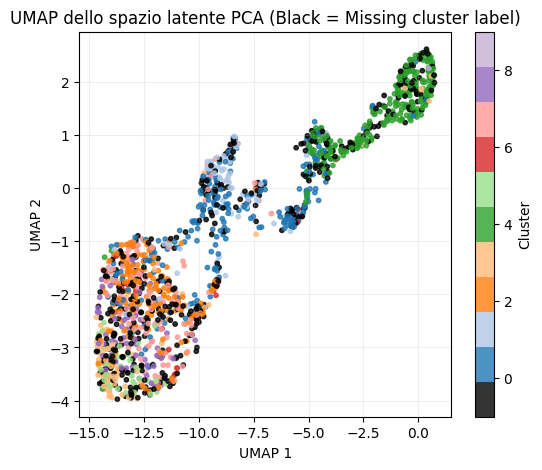

/Users/guth/Coding/AI part 1/Single cell AI/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


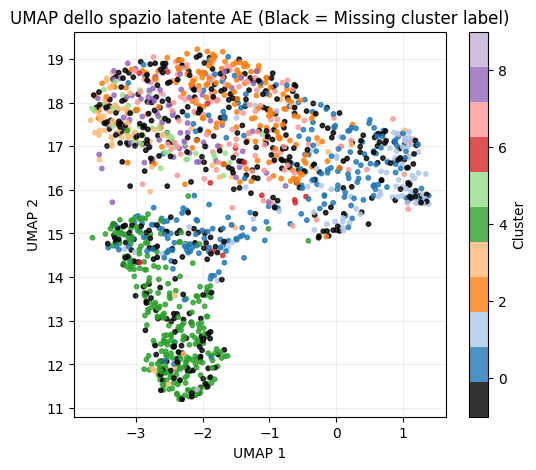

In [47]:
import umap.umap_ as umap
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, Normalize

# Get cluster colors with NaN handling
y_colors = y_full["cluster"].copy()
y_colors = y_colors.fillna(-1)

# Create custom colormap: black for -1 (NaN), then tab20 for clusters
colors = ['black'] + [plt.cm.tab20(i % 20) for i in range(int(y_colors.max()) + 1)]
cmap = ListedColormap(colors[:int(y_colors.max()) + 2])
norm = Normalize(vmin=-1, vmax=y_colors.max())

def plot_umap_single(Z, labels, title):
    """
    Z: matrice (n_cells × latent_dim)
    labels: etichette numeriche per i punti
    title: titolo del grafico
    """
    reducer = umap.UMAP(
        n_components=2,
        random_state=42,
        n_neighbors=15,
        min_dist=0.1
    )

    Z_umap = reducer.fit_transform(Z)

    plt.figure(figsize=(6, 5))
    sc = plt.scatter(
        Z_umap[:, 0],
        Z_umap[:, 1],
    
        c=labels,
        s=10,
        cmap=cmap,
        norm=norm,
        alpha=0.8
    )
    plt.title(title + " (Black = Missing cluster label)")
    plt.xlabel("UMAP 1")
    plt.ylabel("UMAP 2")
    cbar = plt.colorbar(sc)
    cbar.set_label("Cluster")
    plt.grid(alpha=0.2)
    plt.show()


# UMAP dallo spazio latente PCA
plot_umap_single(X_pca_full, y_colors.values, "UMAP dello spazio latente PCA")

# UMAP dallo spazio latente Autoencoder
plot_umap_single(ae_reduced_50, y_colors.values, "UMAP dello spazio latente AE")

### Biological interpretation of the clusters in the AE latent space UMAP

In this UMAP, each point represents one single **blood cell**.
Colors correspond to different clusters (0–9), each linked to a biological cell type:

- 0 → CMP — blue  
- 1 → GMP — light blue  
- 2 → LMPP — orange  
- 3 → LTHSC — light orange  
- 4 → MEP — green  
- 5 → MPP1 — light green  
- 6 → MPP2 — red  
- 7 → MPP3 — pink  
- 8 → STHSC — purple  
- 9 → other — light purple  

These cell types represent different stages of **hematopoiesis**, the biological
process that produces all blood cells (red blood cells, white blood cells and platelets).

Hematopoiesis starts from **Hematopoietic Stem Cells (HSCs)**:

- they can self-renew (produce more stem cells)  
- they can differentiate into all blood lineages  

At a certain point, HSCs split into two major developmental directions:

- **Myeloid lineage** → red blood cells, platelets, macrophages, neutrophils…  
- **Lymphoid lineage** → adaptive immune cells (lymphocytes)  

A simplified lineage path, using cluster labels, is:

**LTHSC (3) → STHSC (8) → MPP1 (5) → MPP2 (6) → MPP3 (7)**

From these multipotent progenitors we then branch into:

- **CMP (0) → GMP (1)** (innate immune branch)  
- **CMP (0) → MEP (4)** (erythro-megakaryocytic branch)  
and a side branch **LMPP (2)**, oriented towards lymphoid potential.




### Hematopoiesis structure (simplified with our clusters)

In [48]:
tree = r"""
                LTHSC (3)
                     ↓
                STHSC (8)
                     ↓
             MPP1/2/3 (5,6,7)
               ┌─────────────┐
               ↓             ↓
          LMPP (2)        CMP (0)
       (lymphoid bias)      │
                            ↓
                     ┌──────┴──────┐
                     ↓             ↓
                  GMP (1)       MEP (4)
        innate immune cells   RBC/platelet lineage
"""
print(tree)


                LTHSC (3)
                     ↓
                STHSC (8)
                     ↓
             MPP1/2/3 (5,6,7)
               ┌─────────────┐
               ↓             ↓
          LMPP (2)        CMP (0)
       (lymphoid bias)      │
                            ↓
                     ┌──────┴──────┐
                     ↓             ↓
                  GMP (1)       MEP (4)
        innate immune cells   RBC/platelet lineage



### Central horizontal region — HSC and multipotent progenitors (clusters 3, 2, 8, 5, 6, 7)

The **central horizontal area** of the UMAP is mainly occupied by:

- LTHSC (cluster 3 – light orange) → Long-Term Hematopoietic Stem Cells  
- STHSC (cluster 8 – purple) → Short-Term Hematopoietic Stem Cells  
- LMPP (cluster 2 - orange)  → Lympho-myeloid primed progenitor cells
- MPP1_broad, MPP2_broad, MPP3_broad (clusters 5 – light green, 6 – red, 7 – pink)

These cells represent a continuum of differentiation:

- LTHSC: truly long-term stem cells
- STHSC: early loss of stemness
- LMPP (2): multipotent cells **biased toward lymphoid fate**,  
- MPP: no longer stem cells, but still multipotent (able to generate multiple cell types) 

For this reason, in the UMAP they appear in the **middle**, forming a **horizontal**
bridge:

• towards the **upper-right** → erythro-megakaryocytic (cluster 4)  
• towards the **lower-left** → innate immunity (clusters 0–1)

Since the dataset does not include fully differentiated lymphoid populations, the future outcome of LMPP is not visible, and they remain in the central area as biased unresolved progenitors.

### Upper-right region — MEP (cluster 4)

The large green group in the **upper-right part** of the UMAP corresponds to
**MEP (cluster 4)**, i.e. Megakaryocyte–Erythroid Progenitors.

These cells will differentiate into:

• red blood cells → specialized in oxygen transport  
• megakaryocytes → precursors of platelets, essential for coagulation  

**Their gene expression program is very different from immune cell progenitors**:
they activate genes related to hemoglobin, heme synthesis and platelet formation,
and do not express the inflammatory and phagocytic programs typical of
innate immune cells.

Because of this strong functional and transcriptional specificity,
cluster 4 (MEP) appears as a compact and clearly separated island
in the **upper-right** of the UMAP.


### Lower-left region — CMP (cluster 0, blue)  
### Lower-center region — GMP (cluster 1, light blue)

In the **bottom-left and bottom-center** of the UMAP we find mainly:

• **CMP (cluster 0 – blue)** – Common Myeloid Progenitors  
  these are “decision-point” progenitors that can still become
  either GMP (innate immunity) or MEP (erythro/megakaryocytic)

  **Because CMP cells can still choose both developmental directions (MEP/GMP), they naturally lie between the large MEP cluster (upper-right) and the GMP area (lower-center), and this transitional positioning is clearly visible in the UMAP.**

• **GMP (cluster 1 – light blue)** – Granulocyte–Monocyte Progenitors  
  progenitors of neutrophils, monocytes, macrophages and other
  cells of the innate immune system

These cells express genes involved in:

- inflammatory responses  
- pathogen detection and killing  
- phagocytosis and migration to sites of infection  

Because their role is to defend the organism from pathogens, their transcriptional
program is biologically opposite to that of MEP (cluster 4), which is
focused on oxygen transport and coagulation.

For this reason, the **lower-left / lower-center** region of the UMAP is dominated by cluster 0 and cluster 1 and represents the **innate immune branch**.

### Cluster 9 — other

Cluster 9 (other - light purple) contains cells that:

• do not match clearly one of the main transcriptional programs above, or  
• may lie in intermediate / mixed states not well captured by the labels  

Therefore they are often **scattered** or appear near boundaries
between well-defined regions.


### Conclusion

The UMAP of the autoencoder latent space does not separate cells randomly.
Instead, it reconstructs a **2D map of hematopoiesis**:

• early HSC and multipotent progenitors (clusters 3, 2, 8, 5, 6, 7) are placed
  in the **center**, as a common starting region  
• the lineage that will generate **red blood cells and platelets**
  (MEP, cluster 4) moves toward a **compact area at the upper-right**  
• the lineage that will generate **innate immune cells**
  (CMP and GMP, clusters 0 and 1) forms the **lower area** of the UMAP  

Highly specialized populations (such as MEP, cluster 4) form
well-separated islands, while more primitive or intermediate cells occupy
the transition zones.

The absence of fully differentiated lymphoid cells in the dataset prevents the LMPP lineage from diverging into its natural direction, leaving these cells located in the center of the UMAP rather than forming a separate branch.

**This shows that the autoencoder latent representation preserves
meaningful biological structure, and the geometry of the UMAP reflects
the real developmental branching of blood cell formation.**

# 11.1 Conclusions on Latent Space Analysis (PCA vs Autoencoder)

The observation of the two UMAP projections — generated from the latent spaces of **PCA** and the **Autoencoder (AE)** — allows for a visual assessment of the quality of the representations produced by each method.

## General patterns observed in the UMAPs

### **1. PCA**
- The latent space obtained with PCA shows a structure distributed across distinct regions, with some areas being denser and others more sparse.
- Although a clear separation between categories does not emerge, the overall geometry appears relatively stable and coherent.
- This behavior reflects the linear nature of PCA: it preserves the main sources of variance but does not capture non-linear relationships in the data.

### **2. Autoencoder**
- The UMAP of the Autoencoder is very similar to that of PCA, with a largely overlapping latent structure in terms of shape and distribution.
- Even though the Autoencoder can learn non-linear transformations, in the analyzed dataset it does not produce a significantly better cluster separation.
- This result is consistent with the Silhouette Score analysis, which shows nearly identical values for PCA and the Autoencoder.

## Overall conclusion

> *PCA and Autoencoder produce latent spaces that, in the analyzed dataset, do not exhibit clear separation between groups.  
> The UMAP projections confirm what was observed with the Silhouette Score: the intrinsic structure of the data does not contain well-defined clusters, regardless of the method used.*

- **The Autoencoder remains the best method in terms of reconstruction error (MSE).**  
- **PCA and the Autoencoder show very similar latent geometries.**

In summary, neither method produces clearly separated clusters, and the differences between the latent representations are mainly qualitative and linked to their different mathematical formulations.  
The dataset appears not to contain strongly distinguishable cluster structures, and this is consistently reflected across both techniques.



# 12 Summary Table of Results

The following table summarizes the performance of the dimensionality reduction methods analyzed, considering both reconstruction error (MSE) and cluster quality measured by the Silhouette Score.

| Method        | Reconstruction Error (MSE) | Silhouette Score | Brief Comment |
|---------------|----------------------------|------------------|----------------|
| **PCA**       | ~4.2–5.0                   | **0.013**        | Linear, stable, does not clearly separate clusters |
| **Autoencoder** | ~3.4–4.7                | **0.009**        | Best MSE, but clusters remain poorly separated |

*Note:* MSE values indicate the observed ranges.  
The Silhouette Scores are very low and similar across methods, indicating that neither PCA nor the Autoencoder produces well-defined clusters in the analyzed dataset.


# 15 Link to the Next Phase: Classification with an MLP

The latent representations obtained with PCA and the Autoencoder are not only useful for visualizing the intrinsic structure of the data, but can also be used as **input for classification models**.

In the next phase of the project, a **Multi-Layer Perceptron (MLP)** will be trained on the different latent representations to compare how each dimensionality reduction method affects the predictive performance of the model.

This will allow us to evaluate:

- which latent space is more informative for classification,
- whether a non-linear technique (Autoencoder) improves performance compared to PCA,
- whether a more compact latent space can facilitate the learning process of a supervised model.

In this way, dimensionality reduction becomes a key step in ensuring effective learning in downstream classification tasks.


## Classification

This process was quite complex, originally we went straight to a pipeline with an AE and a MLP, but we decided to go back to try simpler models, and try ideas with quicker to run models given our limited computational power, we show that process here.

In [50]:
import anndata
import scipy.sparse as sp
import pandas as pd

# --- Load the single-cell dataset ---
df_h5ad = anndata.read_h5ad("single_cell.h5ad")
train_df = pd.read_csv("singlecell_train.csv")

order_df = pd.read_csv("random_singlecell.csv")



In [51]:
#let's create a new df. 
#all data from df_h5ad.X, add an ID column from df_h5ad.obs['ID'], and add a target column from train_df['target'] where the IDs match, for unlabeled data, the target will be -1
#finally, reorder the new df according to order_df['ID']
import numpy as np
data_array = df_h5ad.X.toarray() if sp.issparse(df_h5ad.X) else df_h5ad.X
new_df = pd.DataFrame(data_array, columns=[f'gene_{i}' for i in range(data_array.shape[1])])
new_df['ID'] = df_h5ad.obs['ID'].values
new_df = new_df.merge(train_df[['ID', 'clusters']], on='ID', how='left')
new_df['clusters'] = new_df['clusters'].fillna(-1).astype(int)
new_df = new_df.set_index('ID')
new_df = new_df.reindex(order_df['ID'])

In [52]:
new_df.head()

,gene_0,gene_1,gene_2,gene_3,gene_4,gene_5,gene_6,gene_7,gene_8,gene_9,...,gene_4281,gene_4282,gene_4283,gene_4284,gene_4285,gene_4286,gene_4287,gene_4288,gene_4289,clusters
ID,,,,,,,,,,,,,,,,,,,,,
f8f4122d32,0.0,0.000000,0.000000,0.000000,0.000000,1.118674,8.266439,0.000000,7.292836,8.907288,...,0.000000,0.000000,1.741120,1.741120,1.741120,0.000000,1.741120,0.0,5.979295,2
c547632b57,0.0,1.127610,0.000000,0.000000,0.000000,9.064525,9.480485,1.127610,1.127610,1.127610,...,0.000000,0.000000,2.187418,2.187418,7.887574,1.127610,1.752719,0.0,1.127610,-1
c2e46e7dfc,0.0,5.647103,0.000000,0.000000,0.000000,1.587172,0.000000,0.000000,1.001657,3.324910,...,0.000000,0.000000,7.945814,8.734624,6.957482,2.002485,4.910093,0.0,0.000000,-1
0710f78e38,0.0,0.739977,0.000000,0.000000,0.000000,6.636797,0.739977,7.724014,0.000000,6.877817,...,0.739977,4.304815,0.000000,0.739977,8.035393,1.226692,0.000000,0.0,0.739977,3
449e822f38,0.0,1.929596,2.726607,1.265883,1.265883,2.382454,0.000000,1.265883,0.000000,6.066583,...,1.265883,0.000000,1.265883,10.126408,8.741608,1.265883,0.000000,0.0,0.000000,4


## PCA Dimensionality Reduction Followed by Random Forest and MLP

Despite our earlier dimensionality-reduction analysis, we began by evaluating a simple PCA-based approach as a baseline. Early on, we discovered a core challenge: our validation accuracy did not correlate with the competition website score.
No matter how we tuned the validation scheme (different splits, K-fold, stratification), validation accuracy failed to predict leaderboard performance.

The most plausible explanation is a distribution shift between the labeled dataset (used for training/validation) and the unlabeled dataset (used for scoring). Since the website evaluates only on the unlabeled rows, and these follow a different distribution, validation accuracy becomes unreliable. This mismatch is effectively impossible to eliminate, so instead we attempted to mitigate its effect on the representation.

## Why PCA Needs Adaptation

If labeled and unlabeled samples follow different distributions, fitting PCA only on the labeled subset produces biased PCA directions that do not represent the unlabeled evaluation set. Since the classifier ultimately makes predictions on unlabeled data, this mismatch harms performance.

This motivated our adapted PCA approach, designed to incorporate the unlabeled distribution and correct for dataset shift at test time.

## Adapted PCA Method
1. Fit PCA on the full dataset (labeled + unlabeled)

Normally, PCA is fitted only on training data. Instead, we fit PCA on all samples, which:

aligns principal components with the global structure of the dataset,

prevents PCA from overfitting to labeled samples,

produces more stable, domain-agnostic representations.

This already improves robustness.

2. Train the classifier using the PCA mean

We train the classifier on:

X_pca_train = (X_all - pca.mean_) @ components.T


Using pca.mean_ ensures that training uses the correct PCA coordinate system.
Centering on any other mean (e.g., labeled-only) would distort PCA geometry.

3. At prediction time, re-center using the unlabeled mean

This is the key adaptation step:
we compute

mean_unlabeled = X_unlabeled.mean(axis=0)
X_pca_test = (X_all - mean_unlabeled) @ components.T


The PCA directions remain unchanged, but the origin shifts so that the unlabeled test distribution is better aligned with the training representation.

This compensates for distribution drift and significantly improves generalization.
Using this technique with a simple PCA + RF model improved our leaderboard score by ~0.015 (from ~0.47 to ~0.49).

## Dropping class 9 "other" from classification 

Class 9—labeled as “other”—is extremely small and biologically heterogeneous, making it difficult for a classifier to learn meaningful patterns from it. Including this category during training caused the model to overfit on these few ambiguous samples and introduced instability in the predictions. However, because PCA benefits from capturing the full structure of the dataset, we retain class 9 cells when fitting the dimensionality reduction so that the PCA components reflect the global variance of all samples. We then exclude class 9 from the supervised learning stage and prevent the model from predicting it at inference time. This preserves the representational richness of the full dataset while avoiding the noise and unreliability associated with the “other” class during classification.

## Classifier Comparison: Random Forest vs MLP

We evaluated two classifiers after PCA: a Random Forest (RF) and an MLP.
Both were first run with heuristic hyperparameters, then optimized using grid search and Stratified K-Fold cross-validation.

However, grid search was less effective than expected because validation performance does not reflect leaderboard performance due to the labeled/unlabeled distribution shift.

Why RF Outperforms MLP on This Task

Small, highly imbalanced labeled dataset: MLPs overfit easily, whereas RFs remain stable.

Tabular, low-dimensional PCA features: Random Forests are known to excel in this regime.

Better handling of imbalance: Bootstrapping ensures minority classes contribute to tree splits.

More robust to domain shift: RFs tolerate the difference between labeled and unlabeled distributions better than MLPs.

Overall: RF + Adapted PCA consistently generalizes better than MLP on this dataset.

Given these factors, Random Forests paired with our adapted PCA approach form the most reliable model for this competition.

## Cross-Validation Strategy

All experiments used Stratified K-Fold cross-validation on the labeled subset to preserve class proportions, which is crucial given the extreme class imbalance (some classes contain fewer than 10 examples).



In [54]:
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score
from sklearn.utils.class_weight import compute_class_weight
import numpy as np
import pandas as pd


class SemiSupervisedPCAClassifier:
    def __init__(
        self,
        n_components=50,
        random_state=42,
        backend="rf",          # "rf" or "mlp"
        rf_kwargs=None,
        mlp_kwargs=None,
    ):
        self.n_components = n_components
        self.random_state = random_state
        assert backend in ["rf", "mlp"]
        self.backend = backend

        self.rf_kwargs = rf_kwargs or {}
        self.mlp_kwargs = mlp_kwargs or {}

        self.pca = None
        self.clf = None
        self.feature_cols = None
        self.use_unlabeled_mean = False
        self.mean_train_ = None
        self.mean_unlabeled_ = None

    def fit(self, df, use_unlabeled_mean=False):
        """
        df: DataFrame with at least:
            - feature columns
            - 'clusters' (with -1 for unlabeled)
            - optional 'ID'
        use_unlabeled_mean: if True, store the unlabeled mean for later adaptation.
        """

        self.use_unlabeled_mean = use_unlabeled_mean

        # 1. Extract features (exclude 'clusters' and 'ID')
        self.feature_cols = [c for c in df.columns if c not in ["clusters", "ID"]]
        X = df[self.feature_cols].values
        y = df["clusters"].values

        # 2. Fit PCA on ALL CELLS
        self.pca = PCA(n_components=self.n_components, random_state=self.random_state)
        self.pca.fit(X)
        self.mean_train_ = self.pca.mean_.copy()
        components = self.pca.components_

        # 3. Build PCA features for TRAINING (using training mean)
        X_pca_all = (X - self.mean_train_) @ components.T

        # 4. Labeled subset for classifier training
        mask_labeled = (y != -1) & (y != 9)
        X_labeled = X_pca_all[mask_labeled]
        y_labeled = y[mask_labeled]

        # 5. Possibly compute unlabeled mean in original space
        if use_unlabeled_mean:
            mask_unlabeled = (y == -1)
            if mask_unlabeled.any():
                X_unlabeled = X[mask_unlabeled]
                self.mean_unlabeled_ = X_unlabeled.mean(axis=0)
            else:
                # fallback: if no unlabeled, just use training mean
                self.mean_unlabeled_ = self.mean_train_.copy()
        else:
            self.mean_unlabeled_ = None

        # 6. Build and train classifier
        if self.backend == "rf":
            self._fit_rf(X_labeled, y_labeled)
        elif self.backend == "mlp":
            self._fit_mlp(X_labeled, y_labeled)

        return self

    def _fit_rf(self, X_labeled, y_labeled):
        default_rf_kwargs = dict(
            n_estimators=300,
            min_samples_split=4,
            min_samples_leaf=2,
            class_weight="balanced",
            random_state=self.random_state,
            n_jobs=-1,
        )
        rf_params = {**default_rf_kwargs, **self.rf_kwargs}
        self.clf = RandomForestClassifier(**rf_params)
        self.clf.fit(X_labeled, y_labeled)

    def _fit_mlp(self, X_labeled, y_labeled):
        # Class weights → sample weights (MLP has no class_weight arg)
        classes = np.unique(y_labeled)
        
        class_weights = compute_class_weight(
            class_weight="balanced", classes=classes, y=y_labeled
        )
        cw_dict = {c: w for c, w in zip(classes, class_weights)}
        sample_weight = np.array([cw_dict[c] for c in y_labeled])

        default_mlp_kwargs = dict(
            hidden_layer_sizes=(128, 64),
            activation="relu",
            solver="adam",
            alpha=1e-4,
            batch_size="auto",
            learning_rate="adaptive",
            max_iter=300,
            early_stopping=True,
            n_iter_no_change=10,
            random_state=self.random_state,
            verbose=False,
        )
        mlp_params = {**default_mlp_kwargs, **self.mlp_kwargs}
        self.clf = MLPClassifier(**mlp_params)
        self.clf.fit(X_labeled, y_labeled, sample_weight=sample_weight)

    def _transform_for_prediction(self, df):
        """
        Transform features into PCA space for prediction.
        If use_unlabeled_mean=True and we have mean_unlabeled_,
        re-center with unlabeled mean, but keep same PCA components.
        """
        X = df[self.feature_cols].values
        components = self.pca.components_

        if self.use_unlabeled_mean and (self.mean_unlabeled_ is not None):
            mean_used = self.mean_unlabeled_
        else:
            mean_used = self.mean_train_

        X_pca = (X - mean_used) @ components.T
        return X_pca

    def predict_all(self, df):
        """
        Predict clusters for ALL rows of df (labeled + unlabeled).
        """
        X_pca = self._transform_for_prediction(df)
        preds = self.clf.predict(X_pca)
        return preds

    def evaluate_on_labeled(self, df):
        """
        Compute accuracy on labeled rows of df (clusters != -1),
        using the current transformation strategy.
        """
        y_true = df["clusters"].values
        mask_labeled = (y_true != -1)
        if not mask_labeled.any():
            raise ValueError("No labeled data in df to evaluate on.")

        df_labeled = df[mask_labeled]
        y_true_labeled = y_true[mask_labeled]
        X_pca_labeled = self._transform_for_prediction(df_labeled)
        y_pred_labeled = self.clf.predict(X_pca_labeled)

        acc = accuracy_score(y_true_labeled, y_pred_labeled)
        return acc

    def save_submission(self, df, filename, id_col="ID"):
        """
        Predict on all rows of df and save a CSV with columns:
        - ID
        - clusters (predicted)
        """
        preds_all = self.predict_all(df)

        if id_col in df.columns:
            ids = df[id_col].values
        else:
            ids = df.index

        results_df = pd.DataFrame({
            "ID": ids,
            "clusters": preds_all
        })
        results_df.to_csv(filename, index=False)
        print(f"Saved submission to {filename}")
        return results_df


In [55]:
from sklearn.model_selection import StratifiedKFold

def rf_pca_grid_search(
    df,
    n_components_list=(30, 40, 50),
    n_estimators_list=(200, 400, 800),
    max_depth_list=(None, 15, 25),
    min_samples_leaf_list=(1, 2, 4),
    use_unlabeled_mean=True,
    n_splits=5,
    random_state=42,
):
    """
    Grid search over PCA dims + RF hyperparams using SemiSupervisedPCAClassifier.
    CV is done on labeled data only; unlabeled rows are always included in training
    folds for PCA + unlabeled mean estimation.
    """
    y = df["clusters"].values
    labeled_idx = np.where(y != -1)[0]
    unlabeled_idx = np.where(y == -1)[0]

    y_labeled = y[labeled_idx]

    skf = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=random_state,
    )

    results = []

    for n_comp in n_components_list:
        print(f"\n=== Trying n_components = {n_comp} ===")
        for n_est in n_estimators_list:
            for max_depth in max_depth_list:
                for min_leaf in min_samples_leaf_list:

                    cv_accs = []

                    for fold, (tr_rel, val_rel) in enumerate(skf.split(labeled_idx, y_labeled)):
                        # Map relative indices back to absolute row indices
                        train_labeled_abs = labeled_idx[tr_rel]
                        val_labeled_abs   = labeled_idx[val_rel]

                        # Train df: train-labeled + ALL unlabeled
                        train_indices = np.concatenate([train_labeled_abs, unlabeled_idx])
                        df_train = df.iloc[train_indices].copy()

                        # Val df: only validation labeled rows
                        df_val = df.iloc[val_labeled_abs].copy()

                        # Build classifier for this config
                        rf_kwargs = {
                            "n_estimators": n_est,
                            "max_depth": max_depth,
                            "min_samples_leaf": min_leaf,
                        }
                        clf = SemiSupervisedPCAClassifier(
                            n_components=n_comp,
                            random_state=random_state + fold,
                            backend="rf",
                            rf_kwargs=rf_kwargs,
                        )

                        # Fit on train (with unlabeled-mean trick if requested)
                        clf.fit(df_train, use_unlabeled_mean=use_unlabeled_mean)

                        # Evaluate on labeled validation subset
                        fold_acc = clf.evaluate_on_labeled(df_val)
                        cv_accs.append(fold_acc)

                    mean_acc = float(np.mean(cv_accs))
                    print(
                        f"  n_comp={n_comp}, n_est={n_est}, max_depth={max_depth}, "
                        f"min_leaf={min_leaf} -> CV acc={mean_acc:.4f}"
                    )

                    results.append({
                        "n_components": n_comp,
                        "n_estimators": n_est,
                        "max_depth": max_depth,
                        "min_samples_leaf": min_leaf,
                        "cv_acc": mean_acc,
                    })

    # Sort by CV accuracy descending
    results_sorted = sorted(results, key=lambda d: d["cv_acc"], reverse=True)

    print("\nTop configs:")
    for r in results_sorted[:10]:
        print(r)

    return results_sorted


In [56]:
results = rf_pca_grid_search(
    new_df,
    n_components_list=[30, 35, 40, 45, 50],
    n_estimators_list=[300, 500, 800],
    max_depth_list=[None, 20],
    min_samples_leaf_list=[1, 2],
    use_unlabeled_mean=True,
    n_splits=5,
    random_state=42,
)



=== Trying n_components = 30 ===
  n_comp=30, n_est=300, max_depth=None, min_leaf=1 -> CV acc=0.6350
  n_comp=30, n_est=300, max_depth=None, min_leaf=2 -> CV acc=0.6304
  n_comp=30, n_est=300, max_depth=20, min_leaf=1 -> CV acc=0.6332
  n_comp=30, n_est=300, max_depth=20, min_leaf=2 -> CV acc=0.6313
  n_comp=30, n_est=500, max_depth=None, min_leaf=1 -> CV acc=0.6220
  n_comp=30, n_est=500, max_depth=None, min_leaf=2 -> CV acc=0.6304
  n_comp=30, n_est=500, max_depth=20, min_leaf=1 -> CV acc=0.6239
  n_comp=30, n_est=500, max_depth=20, min_leaf=2 -> CV acc=0.6304
  n_comp=30, n_est=800, max_depth=None, min_leaf=1 -> CV acc=0.6313
  n_comp=30, n_est=800, max_depth=None, min_leaf=2 -> CV acc=0.6322
  n_comp=30, n_est=800, max_depth=20, min_leaf=1 -> CV acc=0.6304
  n_comp=30, n_est=800, max_depth=20, min_leaf=2 -> CV acc=0.6313

=== Trying n_components = 35 ===
  n_comp=35, n_est=300, max_depth=None, min_leaf=1 -> CV acc=0.6192
  n_comp=35, n_est=300, max_depth=None, min_leaf=2 -> CV acc

In [57]:
best_cfg = results[0]
print("\nBest config:", best_cfg)

# Build final RF with best config
best_rf_kwargs = {
    "n_estimators": best_cfg["n_estimators"],
    "max_depth": best_cfg["max_depth"],
    "min_samples_leaf": best_cfg["min_samples_leaf"],
}

best_clf = SemiSupervisedPCAClassifier(
    n_components=best_cfg["n_components"],
    random_state=42,
    backend="rf",
    rf_kwargs=best_rf_kwargs,
)

# Fit on full df (all labeled + unlabeled), with unlabeled-mean recentering
best_clf.fit(new_df, use_unlabeled_mean=True)

# Optional: check labeled accuracy locally
acc_labeled = best_clf.evaluate_on_labeled(new_df)
print(f"Labeled accuracy with best RF+PCA: {acc_labeled:.4f}")

# Save submission CSV
best_clf.save_submission(new_df, "submission_rf_pca_grid_best.csv", id_col="ID")



Best config: {'n_components': 30, 'n_estimators': 300, 'max_depth': None, 'min_samples_leaf': 1, 'cv_acc': 0.635027168006955}
Labeled accuracy with best RF+PCA: 0.9832
Saved submission to submission_rf_pca_grid_best.csv


,ID,clusters
0,f8f4122d32,2
1,c547632b57,2
2,c2e46e7dfc,0
3,0710f78e38,4
4,449e822f38,4
...,...,...
1494,f255ea261b,2
1495,ac69ab7bae,4
1496,12350b2804,4
1497,87cb8c1a31,7


In [58]:
mlp_clf = SemiSupervisedPCAClassifier(
    n_components=50,
    random_state=42,
    backend="mlp",
    mlp_kwargs={
        # you can override defaults here if you want
        # "hidden_layer_sizes": (256, 128),
        # "alpha": 1e-3,
    }
)
mlp_clf.fit(new_df, use_unlabeled_mean=True)
print("MLP labeled acc:", mlp_clf.evaluate_on_labeled(new_df))
mlp_clf.save_submission(new_df, "submission_mlp_50_mean.csv")


MLP labeled acc: 0.9236499068901304
Saved submission to submission_mlp_50_mean.csv


,ID,clusters
0,f8f4122d32,2
1,c547632b57,8
2,c2e46e7dfc,6
3,0710f78e38,3
4,449e822f38,4
...,...,...
1494,f255ea261b,2
1495,ac69ab7bae,4
1496,12350b2804,4
1497,87cb8c1a31,7


In [59]:
rf_clf = SemiSupervisedPCAClassifier(
    n_components=50,
    random_state=42,
    backend="rf",
)
rf_clf.fit(new_df, use_unlabeled_mean=True)  # keep the mean trick that worked
print("RF labeled acc:", rf_clf.evaluate_on_labeled(new_df))
rf_clf.save_submission(new_df, "submission_rf_50_mean.csv")


RF labeled acc: 0.9851024208566108
Saved submission to submission_rf_50_mean.csv


,ID,clusters
0,f8f4122d32,2
1,c547632b57,2
2,c2e46e7dfc,0
3,0710f78e38,4
4,449e822f38,4
...,...,...
1494,f255ea261b,2
1495,ac69ab7bae,4
1496,12350b2804,4
1497,87cb8c1a31,7


In [60]:
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.model_selection import StratifiedKFold
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score  # not used yet but fine

import torch
import torch.nn as nn
import torch.optim as optim

device = torch.device("cuda" if torch.cuda.is_available() else "mps")
print("Using device:", device)


class SimpleMLP(nn.Module):
    def __init__(self, input_dim, hidden_dim, num_classes, dropout=0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, num_classes),
        )

    def forward(self, x):
        return self.net(x)


def train_eval_one_fold(
    X_train, y_train,
    X_val, y_val,
    input_dim, num_classes,
    hidden_dim=128,
    dropout=0.2,
    lr=1e-3,
    weight_decay=0.0,
    epochs=60,
    random_state=42,
):
    torch.manual_seed(random_state)
    np.random.seed(random_state)

    # Move to tensors
    X_train_t = torch.from_numpy(X_train.astype(np.float32)).to(device)
    y_train_t = torch.from_numpy(y_train.astype(np.int64)).to(device)
    X_val_t   = torch.from_numpy(X_val.astype(np.float32)).to(device)
    y_val_t   = torch.from_numpy(y_val.astype(np.int64)).to(device)

    # Class weights → tensor
    classes = np.unique(y_train)
    class_weights = compute_class_weight(
        class_weight="balanced", classes=classes, y=y_train
    )
    # Map weights to each index in y_train
    cw_dict = {c: w for c, w in zip(classes, class_weights)}
    weights_per_sample = np.array([cw_dict[c] for c in y_train], dtype=np.float32)
    weights_per_sample_t = torch.from_numpy(weights_per_sample).to(device)

    model = SimpleMLP(input_dim, hidden_dim, num_classes, dropout=dropout).to(device)
    criterion = nn.CrossEntropyLoss(reduction="none")  # we'll apply sample weights
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    model.train()
    for epoch in range(epochs):
        optimizer.zero_grad()
        logits = model(X_train_t)
        loss_per_sample = criterion(logits, y_train_t)
        loss = (loss_per_sample * weights_per_sample_t).mean()
        loss.backward()
        optimizer.step()

        # Simple sanity print every 20 epochs (optional)
        # if (epoch + 1) % 20 == 0:
        #     with torch.no_grad():
        #         preds_tr = logits.argmax(dim=1)
        #         acc_tr = (preds_tr == y_train_t).float().mean().item()
        #     print(f"Epoch {epoch+1}/{epochs} - train loss {loss.item():.4f} - train acc {acc_tr:.4f}")
    
    # Evaluate on val
    model.eval()
    with torch.no_grad():
        logits_val = model(X_val_t)
        preds_val = logits_val.argmax(dim=1)
        acc_val = (preds_val == y_val_t).float().mean().item()

    return acc_val


def save_mlp_submission(df, preds_all, filename="submission.csv", id_col="ID"):
    """
    Save predictions for all samples into a submission CSV.

    df: original dataframe with ID and clusters columns
    preds_all: numpy array of predicted cluster labels for ALL rows (same order)
    """
    if id_col in df.columns:
        ids = df[id_col].values
    else:
        ids = df.index

    results_df = pd.DataFrame({
        "ID": ids,
        "clusters": preds_all
    })
    results_df.to_csv(filename, index=False)
    print(f"Saved submission to: {filename}")

    return results_df


def grid_search_pca_mlp(
    df,
    n_components_list=[30, 50, 75],
    hidden_list=[64, 128],
    dropout_list=[0.1, 0.3],
    lr_list=[1e-3, 3e-4],
    weight_decay=1e-4,
    epochs=60,
    n_splits=5,
    random_state=42,
):
    # 1. Prepare raw features and labels
    feature_cols = [c for c in df.columns if c not in ["clusters", "ID"]]
    X_raw = df[feature_cols].values.astype(np.float32)
    y_all = df["clusters"].values.astype(int)

    # labeled subset for CV
    mask_labeled = (y_all != -1) & (y_all != 9)
    X_raw_labeled = X_raw[mask_labeled]
    y_labeled = y_all[mask_labeled]

    results = []

    for n_comp in n_components_list:
        print(f"\n=== Trying n_components = {n_comp} ===")
        # Fit PCA on ALL cells once for this n_components
        pca = PCA(n_components=n_comp, random_state=random_state)
        pca.fit(X_raw)
        mean_train = pca.mean_.copy()
        comps = pca.components_

        # PCA features (train mean) for labeled subset
        X_pca_all = (X_raw - mean_train) @ comps.T
        X_pca_labeled = X_pca_all[mask_labeled]

        skf = StratifiedKFold(
            n_splits=n_splits,
            shuffle=True,
            random_state=random_state,
        )

        num_classes = len(np.unique(y_labeled))

        for hidden_dim in hidden_list:
            for dropout in dropout_list:
                for lr in lr_list:
                    fold_accs = []
                    for fold, (tr_idx, val_idx) in enumerate(skf.split(X_pca_labeled, y_labeled)):
                        X_tr = X_pca_labeled[tr_idx]
                        y_tr = y_labeled[tr_idx]
                        X_val = X_pca_labeled[val_idx]
                        y_val = y_labeled[val_idx]

                        acc_val = train_eval_one_fold(
                            X_tr, y_tr,
                            X_val, y_val,
                            input_dim=n_comp,
                            num_classes=num_classes,
                            hidden_dim=hidden_dim,
                            dropout=dropout,
                            lr=lr,
                            weight_decay=weight_decay,
                            epochs=epochs,
                            random_state=random_state + fold,
                        )
                        fold_accs.append(acc_val)

                    mean_acc = float(np.mean(fold_accs))
                    print(
                        f"  n_comp={n_comp}, hidden={hidden_dim}, dropout={dropout}, lr={lr} "
                        f"-> CV acc={mean_acc:.4f}"
                    )
                    results.append({
                        "n_components": n_comp,
                        "hidden_dim": hidden_dim,
                        "dropout": dropout,
                        "lr": lr,
                        "cv_acc": mean_acc,
                    })

    # sort results by cv_acc desc
    results_sorted = sorted(results, key=lambda d: d["cv_acc"], reverse=True)
    print("\nTop configs:")
    for r in results_sorted[:10]:
        print(r)

    return results_sorted


# ---- RUN GRID SEARCH ----
results = grid_search_pca_mlp(
    new_df,
    n_components_list=[30, 35, 40, 45, 50],   # keep small at first
    hidden_list=[64, 128],
    dropout_list=[0.1, 0.3],
    lr_list=[1e-3, 3e-4],
    weight_decay=1e-4,
    epochs=60,
    n_splits=5,
)


Using device: mps

=== Trying n_components = 30 ===
  n_comp=30, hidden=64, dropout=0.1, lr=0.001 -> CV acc=0.5880
  n_comp=30, hidden=64, dropout=0.1, lr=0.0003 -> CV acc=0.5122
  n_comp=30, hidden=64, dropout=0.3, lr=0.001 -> CV acc=0.5693
  n_comp=30, hidden=64, dropout=0.3, lr=0.0003 -> CV acc=0.4710
  n_comp=30, hidden=128, dropout=0.1, lr=0.001 -> CV acc=0.5918
  n_comp=30, hidden=128, dropout=0.1, lr=0.0003 -> CV acc=0.5636
  n_comp=30, hidden=128, dropout=0.3, lr=0.001 -> CV acc=0.5833
  n_comp=30, hidden=128, dropout=0.3, lr=0.0003 -> CV acc=0.5533

=== Trying n_components = 35 ===
  n_comp=35, hidden=64, dropout=0.1, lr=0.001 -> CV acc=0.5936
  n_comp=35, hidden=64, dropout=0.1, lr=0.0003 -> CV acc=0.4719
  n_comp=35, hidden=64, dropout=0.3, lr=0.001 -> CV acc=0.5871
  n_comp=35, hidden=64, dropout=0.3, lr=0.0003 -> CV acc=0.4504
  n_comp=35, hidden=128, dropout=0.1, lr=0.001 -> CV acc=0.6001
  n_comp=35, hidden=128, dropout=0.1, lr=0.0003 -> CV acc=0.5824
  n_comp=35, hidden

In [61]:
def train_best_mlp_and_submit(
    df,
    best_config,
    filename="submission_mlp_pca_mean_best.csv",
    weight_decay=1e-4,
    epochs=80,
    random_state=42,
):
    feature_cols = [c for c in df.columns if c not in ["clusters", "ID"]]
    X_raw = df[feature_cols].values.astype(np.float32)
    y_all = df["clusters"].values.astype(int)

    mask_labeled = (y_all != -1)
    X_raw_labeled = X_raw[mask_labeled]
    y_labeled = y_all[mask_labeled]

    n_comp   = best_config["n_components"]
    hidden   = best_config["hidden_dim"]
    dropout  = best_config["dropout"]
    lr       = best_config["lr"]

    print(f"\nRetraining best MLP with: {best_config}")

    # 1. Fit PCA on ALL cells
    pca = PCA(n_components=n_comp, random_state=random_state)
    pca.fit(X_raw)
    mean_train = pca.mean_.copy()
    comps = pca.components_

    # PCA features (train mean) for labeled
    X_pca_all = (X_raw - mean_train) @ comps.T
    X_pca_labeled = X_pca_all[mask_labeled]

    # 2. Compute unlabeled mean in original space (for test-time projection)
    mask_unlabeled = (y_all == -1)
    if mask_unlabeled.any():
        X_unlab = X_raw[mask_unlabeled]
        mean_unlab = X_unlab.mean(axis=0)
    else:
        mean_unlab = mean_train

    # 3. Train final MLP on all labeled data
    torch.manual_seed(random_state)
    np.random.seed(random_state)

    X_t = torch.from_numpy(X_pca_labeled.astype(np.float32)).to(device)
    y_t = torch.from_numpy(y_labeled.astype(np.int64)).to(device)

    classes = np.unique(y_labeled)
    class_weights = compute_class_weight(
        class_weight="balanced", classes=classes, y=y_labeled
    )
    cw_dict = {c: w for c, w in zip(classes, class_weights)}
    weights_per_sample = np.array([cw_dict[c] for c in y_labeled], dtype=np.float32)
    weights_per_sample_t = torch.from_numpy(weights_per_sample).to(device)

    model = SimpleMLP(
        input_dim=n_comp,
        hidden_dim=hidden,
        num_classes=len(classes),
        dropout=dropout,
    ).to(device)

    criterion = nn.CrossEntropyLoss(reduction="none")
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    model.train()
    for epoch in range(epochs):
        optimizer.zero_grad()
        logits = model(X_t)
        loss_per_sample = criterion(logits, y_t)
        loss = (loss_per_sample * weights_per_sample_t).mean()
        loss.backward()
        optimizer.step()

        if (epoch + 1) % 20 == 0:
            with torch.no_grad():
                preds_tr = logits.argmax(1)
                acc_tr = (preds_tr == y_t).float().mean().item()
            print(f"Epoch {epoch+1}/{epochs} - loss={loss.item():.4f} - train_acc={acc_tr:.4f}")

    # 4. Predict all cells using unlabeled-mean projection
    X_pca_pred = (X_raw - mean_unlab) @ comps.T
    X_pred_t = torch.from_numpy(X_pca_pred.astype(np.float32)).to(device)

    model.eval()
    with torch.no_grad():
        logits_all = model(X_pred_t)
        preds_all = logits_all.argmax(1).cpu().numpy()

    # 5. Save submission CSV
    sub_df = save_mlp_submission(df, preds_all, filename=filename, id_col="ID")
    return model, pca, sub_df


In [62]:
best_cfg = results[0]  # best from grid_search_pca_mlp
model, pca, sub_df = train_best_mlp_and_submit(
    new_df,
    best_cfg,
    filename="submission_mlp_pca_mean_best.csv",
    epochs=80,
)



Retraining best MLP with: {'n_components': 50, 'hidden_dim': 128, 'dropout': 0.1, 'lr': 0.001, 'cv_acc': 0.6114211678504944}
Epoch 20/80 - loss=1.1062 - train_acc=0.6015
Epoch 40/80 - loss=0.7395 - train_acc=0.7104
Epoch 60/80 - loss=0.5566 - train_acc=0.7607
Epoch 80/80 - loss=0.4238 - train_acc=0.8194
Saved submission to: submission_mlp_pca_mean_best.csv


## Recap

Our initial PCA + Random Forest pipeline performed surprisingly well, reaching a leaderboard accuracy of 0.499, compared to a current top score of around 0.55. Through iterative experimentation, we gained several important insights into both the dataset and the behaviour of different models:

Dropping class 9 (“other”) improves performance, as this class is extremely small, heterogeneous, and adds noise to supervised learning.

Adapting PCA at prediction time is crucial: re-centering PCA features using the unlabeled mean significantly improves generalization to the evaluation set and helps mitigate distribution shift.

MLPs are not necessarily better than RFs: due to the small and highly imbalanced training set, neural networks overfit easily, while Random Forests remain stable and robust.

Stratified K-Fold is essential due to extreme class imbalance, though it still cannot fully simulate the unlabeled evaluation distribution.

## Autoencoder + Random Forest Pipeline — Summary

### Motivation

While PCA + RF already performed well, we wanted a more expressive low-dimensional representation capable of capturing non-linear gene–gene relationships. Autoencoders are well suited for this because they learn a compressed representation (latent space) optimized for reconstruction. However, AE performance can degrade under distribution shift between labeled and unlabeled cells. We designed a semi-supervised AE pipeline that explicitly addresses this issue.

### Pipeline Overview
#### 1. Train a Denoising Autoencoder on all cells

We normalize all input features and train a small denoising autoencoder on the full dataset (both labeled and unlabeled).
This gives us a latent embedding of size d (e.g., 50), capturing the global structure of all samples.

#### 2. Compute latent codes for all cells

After training, we encode every cell into the latent space.
This is the representation used for classification.

#### 3. Correct for distribution shift between labeled and unlabeled cells

Labeled and unlabeled cells come from slightly different distributions.
To account for this, we compute:

the mean latent vector of labeled cells

the mean latent vector of unlabeled cells

Then, at prediction time, we shift latent vectors so they are aligned with the labeled distribution.
This is the latent-space analogue of the adapted PCA trick that improved earlier results.

#### 4. Train a Random Forest classifier on labeled latent embeddings

We drop class “9” (“other”), since keeping it consistently hurts performance and is not evaluated by the leaderboard.
RF is trained with sample-level class balancing to handle severe class imbalance.

#### 5. Make predictions on all cells (labeled + unlabeled)

Using the shifted latent representation and RF, we generate predictions for all 1500 cells for submission.

### Why This Works Better
✓ The autoencoder sees all data, not just the sparse labeled set

It learns a geometry that respects the full distribution of cells.

✓ Latent shift reduces mismatch between training and evaluation distributions

The leaderboard evaluates only unlabeled cells, so aligning latent spaces empirically boosts performance.

✓ RF is more stable than MLP on low-sample, imbalanced classification

The AE provides the expressive representation; RF provides robust decision boundaries.

✓ Class 9 removal reduces noise

“Other” is not a meaningful or consistent pattern, and dropping it improves generalization.

In [72]:
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset, random_split

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.utils.class_weight import compute_class_weight


device = torch.device("cuda" if torch.cuda.is_available() else "mps")
print("Using device:", device)


# =========================
# 1. Autoencoder definition
# =========================

class DenoisingAE(nn.Module):
    def __init__(self, input_dim, latent_dim=32, hidden_dim=128, dropout=0.2):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, latent_dim),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, input_dim),
        )

    def forward(self, x):
        z = self.encoder(x)
        recon = self.decoder(z)
        return recon

    def encode(self, x):
        return self.encoder(x)


def train_autoencoder(
    X_all,
    latent_dim=32,
    hidden_dim=128,
    dropout=0.2,
    noise_std=0.05,
    batch_size=64,
    lr=1e-3,
    weight_decay=1e-4,
    max_epochs=200,
    patience=15,
    val_fraction=0.1,
    random_state=42,
):
    """
    Train a denoising AE on ALL cells.
    X_all: np.ndarray of shape (n_samples, n_features), already normalized.
    Returns: trained model (best val), input_dim
    """

    torch.manual_seed(random_state)
    np.random.seed(random_state)

    n_samples, input_dim = X_all.shape
    X_tensor = torch.from_numpy(X_all.astype(np.float32))

    # Build dataset and train/val split
    dataset = TensorDataset(X_tensor)
    n_val = max(1, int(val_fraction * n_samples))
    n_train = n_samples - n_val
    train_ds, val_ds = random_split(
        dataset,
        [n_train, n_val],
        generator=torch.Generator().manual_seed(random_state),
    )

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, drop_last=False)
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False, drop_last=False)

    model = DenoisingAE(input_dim, latent_dim=latent_dim, hidden_dim=hidden_dim, dropout=dropout).to(device)
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    criterion = nn.MSELoss()

    best_val_loss = float("inf")
    best_state = None
    epochs_no_improve = 0

    for epoch in range(max_epochs):
        # ---- Train ----
        model.train()
        train_loss = 0.0
        for (xb,) in train_loader:
            xb = xb.to(device)
            # Denoising: add Gaussian noise to input
            noise = torch.randn_like(xb) * noise_std
            xb_noisy = xb + noise

            optimizer.zero_grad()
            recon = model(xb_noisy)
            loss = criterion(recon, xb)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * xb.size(0)

        train_loss /= n_train

        # ---- Validation ----
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for (xb,) in val_loader:
                xb = xb.to(device)
                recon = model(xb)
                loss = criterion(recon, xb)
                val_loss += loss.item() * xb.size(0)
        val_loss /= n_val

        # Early stopping
        if val_loss < best_val_loss - 1e-5:
            best_val_loss = val_loss
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1

        # Optional print
        # if (epoch + 1) % 20 == 0:
        #     print(f"Epoch {epoch+1}/{max_epochs} - train {train_loss:.4f} | val {val_loss:.4f}")

        if epochs_no_improve >= patience:
            # print(f"Early stopping at epoch {epoch+1}")
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    return model, input_dim


# ==========================================
# 2. Semi-supervised AE + RF classification
# ==========================================

class SemiSupervisedAEClassifier:
    """
    Autoencoder + latent RF classifier with unlabeled adaptation, similar to the PCA pipeline.

    - AE trained on ALL cells (labeled + unlabeled)
    - Latent features used for RF
    - Class 9 ("other") dropped from classifier training and never predicted
    - Latent mean-shift between labeled and unlabeled domain (optional)
    """

    def __init__(
        self,
        latent_dim=32,
        ae_hidden_dim=128,
        ae_dropout=0.2,
        ae_noise_std=0.05,
        ae_batch_size=64,
        ae_lr=1e-3,
        ae_weight_decay=1e-4,
        ae_max_epochs=200,
        ae_patience=15,
        random_state=42,
        use_unlabeled_latent_shift=True,
        alpha_latent_shift=1.0,   # NEW: strength of latent shift
        rf_kwargs=None,
    ):
        self.latent_dim = latent_dim
        self.ae_hidden_dim = ae_hidden_dim
        self.ae_dropout = ae_dropout
        self.ae_noise_std = ae_noise_std
        self.ae_batch_size = ae_batch_size
        self.ae_lr = ae_lr
        self.ae_weight_decay = ae_weight_decay
        self.ae_max_epochs = ae_max_epochs
        self.ae_patience = ae_patience
        self.random_state = random_state

        self.use_unlabeled_latent_shift = use_unlabeled_latent_shift
        self.alpha_latent_shift = alpha_latent_shift  # NEW

        self.rf_kwargs = rf_kwargs or {}

        self.feature_cols = None
        self.input_mean_ = None
        self.input_std_ = None

        self.ae = None
        self.clf = None

        self.latent_mean_labeled_ = None
        self.latent_mean_unlabeled_ = None

    def _normalize(self, X):
        return (X - self.input_mean_) / self.input_std_

    def fit(self, df):
        """
        df: DataFrame with feature columns, 'clusters', and optional 'ID'.
        Trains AE on all cells, then trains RF on labeled latent codes (excluding class 9).
        """
        np.random.seed(self.random_state)
        torch.manual_seed(self.random_state)

        # 1. Extract features and labels
        self.feature_cols = [c for c in df.columns if c not in ["clusters", "ID"]]
        X = df[self.feature_cols].values.astype(np.float32)
        y = df["clusters"].values.astype(int)

        # 2. Compute input normalization on ALL cells
        self.input_mean_ = X.mean(axis=0, keepdims=True)
        self.input_std_ = X.std(axis=0, keepdims=True)
        self.input_std_[self.input_std_ < 1e-6] = 1e-6  # avoid division by zero
        X_norm = self._normalize(X)

        # 3. Train AE on all normalized cells
        self.ae, input_dim = train_autoencoder(
            X_norm,
            latent_dim=self.latent_dim,
            hidden_dim=self.ae_hidden_dim,
            dropout=self.ae_dropout,
            noise_std=self.ae_noise_std,
            batch_size=self.ae_batch_size,
            lr=self.ae_lr,
            weight_decay=self.ae_weight_decay,
            max_epochs=self.ae_max_epochs,
            patience=self.ae_patience,
            val_fraction=0.1,
            random_state=self.random_state,
        )

        # 4. Compute latent codes for all cells
        self.ae.eval()
        with torch.no_grad():
            X_norm_t = torch.from_numpy(X_norm).to(device)
            Z_all_t = self.ae.encode(X_norm_t)
            Z_all = Z_all_t.cpu().numpy()

        # 5. Compute latent means for labeled and unlabeled (for adaptation)
        mask_labeled = (y != -1)
        mask_unlabeled = (y == -1)

        if mask_labeled.any():
            self.latent_mean_labeled_ = Z_all[mask_labeled].mean(axis=0, keepdims=True)
        else:
            self.latent_mean_labeled_ = np.zeros((1, self.latent_dim), dtype=np.float32)

        if mask_unlabeled.any():
            self.latent_mean_unlabeled_ = Z_all[mask_unlabeled].mean(axis=0, keepdims=True)
        else:
            self.latent_mean_unlabeled_ = self.latent_mean_labeled_.copy()

        # 6. Build training set for RF: labeled only, drop class 9 ("other")
        mask_train = (y != -1) & (y != 9)
        Z_train = Z_all[mask_train]
        y_train = y[mask_train]

        # 7. Train RF with class weights
        classes = np.unique(y_train)
        class_weights = compute_class_weight(
            class_weight="balanced",
            classes=classes,
            y=y_train,
        )
        cw_dict = {c: w for c, w in zip(classes, class_weights)}

        # Convert to sample weights
        sample_weight = np.array([cw_dict[c] for c in y_train], dtype=np.float32)

        default_rf_kwargs = dict(
            n_estimators=300,
            min_samples_split=4,
            min_samples_leaf=2,
            class_weight=None,  # we handle imbalance via sample_weight
            random_state=self.random_state,
            n_jobs=-1,
        )
        rf_params = {**default_rf_kwargs, **self.rf_kwargs}

        self.clf = RandomForestClassifier(**rf_params)
        self.clf.fit(Z_train, y_train, sample_weight=sample_weight)

        return self

    def _encode_and_adapt(self, df, alpha=None):
        """
        Encode all rows of df into latent space and optionally
        apply unlabeled-latent mean shift for prediction.
        alpha: strength of shift; if None, uses self.alpha_latent_shift.
        """
        if alpha is None:
            alpha = self.alpha_latent_shift

        X = df[self.feature_cols].values.astype(np.float32)
        X_norm = self._normalize(X)

        self.ae.eval()
        with torch.no_grad():
            X_norm_t = torch.from_numpy(X_norm).to(device)
            Z_all_t = self.ae.encode(X_norm_t)
            Z_all = Z_all_t.cpu().numpy()

        if self.use_unlabeled_latent_shift:
            # Z' = Z - α * μ_unlab + α * μ_lab
            Z_all_shifted = Z_all - alpha * self.latent_mean_unlabeled_ + alpha * self.latent_mean_labeled_
            return Z_all_shifted
        else:
            return Z_all

    def predict_all(self, df, alpha=None):
        """
        Predict clusters for ALL rows (labeled + unlabeled).
        We never output class 9 ("other"): predictions of 9 are remapped to -1.
        alpha: optional override for latent shift strength.
        """
        Z_all_pred = self._encode_and_adapt(df, alpha=alpha)
        preds = self.clf.predict(Z_all_pred)

        # Never output class 9
        preds = np.where(preds == 9, -1, preds)
        return preds

    def evaluate_on_labeled(self, df, alpha=None):
        """
        Accuracy on labeled rows (clusters != -1),
        using the current AE + RF + latent shift.
        alpha: optional override for latent shift strength.
        """
        y_true = df["clusters"].values.astype(int)
        mask_labeled = (y_true != -1)
        if not mask_labeled.any():
            raise ValueError("No labeled data to evaluate on.")

        df_labeled = df[mask_labeled].copy()
        y_true_labeled = y_true[mask_labeled]

        Z_labeled_pred = self._encode_and_adapt(df_labeled, alpha=alpha)
        y_pred_labeled = self.clf.predict(Z_labeled_pred)

        # No prediction of class 9
        y_pred_labeled = np.where(y_pred_labeled == 9, -1, y_pred_labeled)

        acc = accuracy_score(y_true_labeled, y_pred_labeled)
        return acc

    def save_submission(self, df, filename="submission_ae_rf.csv", id_col="ID", alpha=None):
        """
        Predict on all rows of df and save:
        - ID
        - clusters (predicted)
        alpha: optional override for latent shift strength.
        """
        preds_all = self.predict_all(df, alpha=alpha)

        if id_col in df.columns:
            ids = df[id_col].values
        else:
            ids = df.index

        results_df = pd.DataFrame({
            "ID": ids,
            "clusters": preds_all,
        })
        results_df.to_csv(filename, index=False)
        print(f"Saved submission to {filename}")
        return results_df


# ===========================
# Example usage with new_df
# ===========================


Using device: mps


In [64]:
ae_clf = SemiSupervisedAEClassifier(
    latent_dim=50,          # you can try 16, 32, 64
    ae_hidden_dim=128,
    ae_dropout=0.2,
    ae_noise_std=0.05,
    use_unlabeled_latent_shift=True,  # the adapted PCA idea in latent space
    alpha_latent_shift=1.0,           # try 0.5, 0.7, 1.0, etc.
    rf_kwargs={
        "n_estimators": 320,
        "max_depth": None,
        "min_samples_leaf": 2,
    },
    random_state=42,
)

ae_clf.fit(new_df)
print("AE + RF labeled acc (alpha=1.0):", ae_clf.evaluate_on_labeled(new_df, alpha=1.0))

ae_clf.save_submission(new_df, "submission_ae_rf_latentshift_alpha1_0.csv", alpha=1.0)

AE + RF labeled acc (alpha=1.0): 0.9674115456238361
Saved submission to submission_ae_rf_latentshift_alpha1_0.csv


,ID,clusters
0,f8f4122d32,2
1,c547632b57,2
2,c2e46e7dfc,0
3,0710f78e38,4
4,449e822f38,4
...,...,...
1494,f255ea261b,2
1495,ac69ab7bae,4
1496,12350b2804,4
1497,87cb8c1a31,7


In [65]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score

def ensemble_predict_all(rf_clf, ae_clf, df, alpha=None):
    """
    Ensemble of PCA+RF and AE+RF.

    - If both models agree → keep that label
    - If they disagree → take the model whose predicted class has *higher probability*
    """

    # --- PCA+RF predictions + probabilities ---
    preds_rf = rf_clf.predict_all(df)
    X_rf = rf_clf._transform_for_prediction(df)
    probs_rf = rf_clf.clf.predict_proba(X_rf)
    classes_rf = rf_clf.clf.classes_

    # --- AE+RF predictions + probabilities ---
    try:
        preds_ae = ae_clf.predict_all(df, alpha=alpha)
        Z_ae = ae_clf._encode_and_adapt(df, alpha=alpha)
    except TypeError:
        preds_ae = ae_clf.predict_all(df)
        Z_ae = ae_clf._encode_and_adapt(df)

    probs_ae = ae_clf.clf.predict_proba(Z_ae)
    classes_ae = ae_clf.clf.classes_

    # --- Final ensemble ---
    ensemble_preds = []
    for i, (pr, pa) in enumerate(zip(preds_rf, preds_ae)):

        if pr == pa:
            # agree → keep prediction
            ensemble_preds.append(pa)
            continue

        # disagreement → compare probabilities

        # probability RF assigns to its predicted class
        idx_rf = np.where(classes_rf == pr)[0][0]
        prob_rf = probs_rf[i, idx_rf]

        # probability AE assigns to its predicted class
        idx_ae = np.where(classes_ae == pa)[0][0]
        prob_ae = probs_ae[i, idx_ae]

        # choose higher-confidence prediction
        if prob_ae >= prob_rf:
            ensemble_preds.append(pa)
        else:
            ensemble_preds.append(pr)

    return np.array(ensemble_preds)


def ensemble_evaluate_on_labeled(rf_clf, ae_clf, df, alpha=None):
    y_true = df["clusters"].values.astype(int)
    mask_labeled = (y_true != -1)
    if not mask_labeled.any():
        raise ValueError("No labeled data to evaluate on.")

    df_labeled = df[mask_labeled].copy()
    y_true_labeled = y_true[mask_labeled]

    ensemble_preds = ensemble_predict_all(rf_clf, ae_clf, df_labeled, alpha=alpha)
    acc = accuracy_score(y_true_labeled, ensemble_preds)
    return acc


def save_ensemble_submission(
    rf_clf,
    ae_clf,
    df,
    filename="submission_ensemble.csv",
    id_col="ID",
    alpha=None,
):
    preds_all = ensemble_predict_all(rf_clf, ae_clf, df, alpha=alpha)

    if id_col in df.columns:
        ids = df[id_col].values
    else:
        ids = df.index

    results_df = pd.DataFrame({
        "ID": ids,
        "clusters": preds_all,
    })
    results_df.to_csv(filename, index=False)
    print(f"Saved ensemble submission to {filename}")
    return results_df


In [66]:
acc_ens = ensemble_evaluate_on_labeled(rf_clf, ae_clf, new_df, alpha=1.0)
print(f"Ensemble labeled acc (alpha={1.0}): {acc_ens:.4f}")

fname = f"submission_ensemble_alpha{str(1.0).replace('.', '_')}.csv"
save_ensemble_submission(rf_clf, ae_clf, new_df, filename=fname, alpha=1.0)


Ensemble labeled acc (alpha=1.0): 0.9749
Saved ensemble submission to submission_ensemble_alpha1_0.csv


,ID,clusters
0,f8f4122d32,2
1,c547632b57,2
2,c2e46e7dfc,0
3,0710f78e38,4
4,449e822f38,4
...,...,...
1494,f255ea261b,2
1495,ac69ab7bae,4
1496,12350b2804,4
1497,87cb8c1a31,7


In [67]:
import numpy as np
import pandas as pd
from sklearn.utils.class_weight import compute_class_weight
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

def pseudo_label_retrain_ae_rf(
    ae_clf,
    df,
    alpha=1.0,
    prob_threshold=0.9,
    max_pseudo=None,
):
    """
    Self-training / pseudo-labeling on top of an already fitted SemiSupervisedAEClassifier.

    Steps:
      - Compute latent features with _encode_and_adapt(df, alpha)
      - Get predictions + probabilities on unlabeled cells (clusters == -1)
      - Keep only unlabeled cells with max proba >= prob_threshold
      - Optionally cap the number of pseudo-labeled points with max_pseudo
      - Retrain RF on labeled + pseudo-labeled latent features
      - Replace ae_clf.clf with the new RF

    Returns:
      - new_clf (RandomForestClassifier)
      - info dict with counts and diagnostics
    """

    # 1. Extract labels
    y_full = df["clusters"].values.astype(int)
    mask_labeled = (y_full != -1)
    mask_unlabeled = (y_full == -1)

    if not mask_unlabeled.any():
        print("No unlabeled data found (clusters == -1). Nothing to pseudo-label.")
        return ae_clf.clf, {"n_pseudo": 0}

    # 2. Compute latent features with adaptation (same space as used at inference)
    Z_all = ae_clf._encode_and_adapt(df, alpha=alpha)

    Z_labeled = Z_all[mask_labeled]
    y_labeled = y_full[mask_labeled]

    Z_unlabeled = Z_all[mask_unlabeled]

    # 3. Current RF predictions and probabilities on UNLABELED
    probs_unlab = ae_clf.clf.predict_proba(Z_unlabeled)
    class_labels = ae_clf.clf.classes_  # e.g. [0,1,2,3,4,5,6,7,8]

    class_idx_max = np.argmax(probs_unlab, axis=1)
    y_pseudo = class_labels[class_idx_max]
    p_max = probs_unlab[np.arange(len(probs_unlab)), class_idx_max]

    # 4. Filter by confidence threshold
    mask_confident = (p_max >= prob_threshold)
    if not mask_confident.any():
        print(f"No pseudo-labels above threshold={prob_threshold}.")
        return ae_clf.clf, {"n_pseudo": 0}

    Z_pseudo = Z_unlabeled[mask_confident]
    y_pseudo_conf = y_pseudo[mask_confident]
    p_pseudo_conf = p_max[mask_confident]

    # Optionally cap number of pseudo-labeled samples
    if max_pseudo is not None and max_pseudo < len(Z_pseudo):
        # Keep the highest-confidence ones
        sort_idx = np.argsort(-p_pseudo_conf)  # descending by prob
        keep_idx = sort_idx[:max_pseudo]
        Z_pseudo = Z_pseudo[keep_idx]
        y_pseudo_conf = y_pseudo_conf[keep_idx]
        p_pseudo_conf = p_pseudo_conf[keep_idx]

    n_pseudo = len(Z_pseudo)
    print(f"Using {n_pseudo} pseudo-labeled unlabeled samples (threshold={prob_threshold}).")

    # 5. Build new training set in latent space
    Z_train_new = np.vstack([Z_labeled, Z_pseudo])
    y_train_new = np.concatenate([y_labeled, y_pseudo_conf])

    # 6. Train new RF with class weights
    classes = np.unique(y_train_new)
    class_weights = compute_class_weight(
        class_weight="balanced",
        classes=classes,
        y=y_train_new,
    )
    cw_dict = {c: w for c, w in zip(classes, class_weights)}
    sample_weight = np.array([cw_dict[c] for c in y_train_new], dtype=np.float32)

    # reuse ae_clf's RF hyperparams
    default_rf_kwargs = dict(
        n_estimators=300,
        min_samples_split=4,
        min_samples_leaf=2,
        class_weight=None,
        random_state=ae_clf.random_state,
        n_jobs=-1,
    )
    rf_params = {**default_rf_kwargs, **ae_clf.rf_kwargs}
    new_clf = RandomForestClassifier(**rf_params)
    new_clf.fit(Z_train_new, y_train_new, sample_weight=sample_weight)

    # 7. Replace classifier inside ae_clf
    ae_clf.clf = new_clf

    # 8. Optionally compute labeled accuracy after retrain
    acc_labeled = ae_clf.evaluate_on_labeled(df, alpha=alpha)
    print(f"New AE+RF (with pseudo-labels) labeled acc: {acc_labeled:.4f}")

    info = {
        "n_pseudo": n_pseudo,
        "prob_threshold": prob_threshold,
        "classes_used": classes,
        "acc_labeled_after": acc_labeled,
    }
    return new_clf, info


In [68]:
# Before pseudo-labeling
print("Baseline AE+RF labeled acc:", ae_clf.evaluate_on_labeled(new_df, alpha=1.0))

# Do one round of pseudo-label self-training
new_clf, info = pseudo_label_retrain_ae_rf(
    ae_clf,
    new_df,
    alpha=1.0,          # same latent shift you use at inference
    prob_threshold=0.98, # you can try 0.85, 0.9, 0.95
    max_pseudo=None,    # or e.g. 200 to limit added samples
)

print("Info:", info)

# Build new submission after pseudo-labeling
ae_clf.save_submission(new_df, "submission_ae_rf_pseudolabels.csv", alpha=1.0)


Baseline AE+RF labeled acc: 0.9674115456238361
Using 3 pseudo-labeled unlabeled samples (threshold=0.98).
New AE+RF (with pseudo-labels) labeled acc: 0.9898
Info: {'n_pseudo': 3, 'prob_threshold': 0.98, 'classes_used': array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), 'acc_labeled_after': 0.9897579143389199}
Saved submission to submission_ae_rf_pseudolabels.csv


,ID,clusters
0,f8f4122d32,2
1,c547632b57,2
2,c2e46e7dfc,0
3,0710f78e38,3
4,449e822f38,4
...,...,...
1494,f255ea261b,2
1495,ac69ab7bae,4
1496,12350b2804,4
1497,87cb8c1a31,7


In [69]:
from sklearn.preprocessing import KBinsDiscretizer

def build_binned_df(input_df, n_bins=4, strategy="quantile", prefix="bin_"):
    """
    Take a dataframe with log1p-normalized expression values and 'clusters' (and optional 'ID'),
    and return a new dataframe where feature columns are discretized into bins.

    - n_bins: number of bins (e.g. 3, 4, 5)
    - strategy: 'quantile' (recommended), 'uniform', or 'kmeans'
    - prefix: prefix for binned feature column names
    """
    # 1. Separate feature cols from labels / ID
    non_feature_cols = [c for c in ["clusters", "ID"] if c in input_df.columns]
    feature_cols = [c for c in input_df.columns if c not in non_feature_cols]

    X = input_df[feature_cols].values.astype(np.float32)

    # 2. Fit KBinsDiscretizer on ALL cells (labeled + unlabeled)
    kb = KBinsDiscretizer(
        n_bins=n_bins,
        encode="ordinal",     # we want 0,1,2,...,n_bins-1
        strategy=strategy,    # 'quantile' = each bin has similar # of cells
    )
    X_binned = kb.fit_transform(X)

    # 3. Build a new df with binned features
    binned_feature_cols = [f"{prefix}{c}" for c in feature_cols]
    binned_df = pd.DataFrame(
        X_binned,
        columns=binned_feature_cols,
        index=input_df.index,
    )

    # 4. Attach clusters (and ID if present)
    for col in non_feature_cols:
        binned_df[col] = input_df[col].values

    return binned_df, kb


In [ ]:
binned_df, kb = build_binned_df(new_df, n_bins=4, strategy="quantile")

binned_df.head()


In [71]:
# AE + RF on binned data
ae_clf_binned = SemiSupervisedAEClassifier(
    latent_dim=50,          # you can also try 32 or 64 here
    ae_hidden_dim=128,
    ae_dropout=0.2,
    ae_noise_std=0.05,      # (optional) slightly lower noise for binned features
    use_unlabeled_latent_shift=True,
    alpha_latent_shift=1.0,
    rf_kwargs={
        "n_estimators": 320,
        "max_depth": None,
        "min_samples_leaf": 2,
    },
    random_state=42,
)

ae_clf_binned.fit(binned_df)
print("AE + RF (binned) labeled acc:", ae_clf_binned.evaluate_on_labeled(binned_df, alpha=1.0))

ae_clf_binned.save_submission(
    binned_df,
    filename="submission_ae_rf_binned_50_alpha1_0.csv",
    alpha=1.0,
)


AE + RF (binned) labeled acc: 0.9776536312849162
Saved submission to submission_ae_rf_binned_50_alpha1_0.csv


,ID,clusters
0,f8f4122d32,2
1,c547632b57,2
2,c2e46e7dfc,0
3,0710f78e38,4
4,449e822f38,4
...,...,...
1494,f255ea261b,2
1495,ac69ab7bae,4
1496,12350b2804,4
1497,87cb8c1a31,7


## Performance Recap

The AE + RF latent-shift model achieves ~0.528 leaderboard accuracy, significantly better than PCA baselines.

Increasing latent dimension helps only if the RF is regularized (e.g., deeper trees, slightly higher min_samples_leaf).

Incorporating binning or alternative input normalizations provides marginal changes, but AE remains robust.

We also try more advances techniques such as creating pseudo labels and applying a quantile binning strategies, but they all slightly underperform our AE + RF pipeline.

## Key Takeaways

Autoencoders provide a powerful non-linear embedding that improves downstream classification when labeled data is scarce.

Correcting for distribution shift is essential; otherwise the AE learns a latent space misaligned with test-time samples.

RF remains a highly competitive classifier in low-data regimes, often outperforming MLPs due to stability and simplicity.

The combination AE + latent shift + RF is one of the most effective semi-supervised pipelines for this task.